In [43]:
# set working directory to the script's directory
import os

# Set your desired path
# os.chdir("/workspaces/microsplit_DOL")
os.chdir("/Users/valentingoupille/Desktop/microsplit_DOL")

# Check if it worked
print("Current working directory:", os.getcwd())

os.listdir()


# These imports and path modifications are only necessary for development
import importlib

import os
import sys

module_path = os.path.abspath(os.path.join(".."))
if module_path not in sys.path:
    sys.path.append(module_path)

Current working directory: /Users/valentingoupille/Desktop/microsplit_DOL


In [44]:
!pip install KDEpy


[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: python3.11 -m pip install --upgrade pip


In [45]:
import pandas as pd
import scanpy as sc
import anndata as ad
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.sparse as sps

import BacSC2.util_probe as up
import BacSC2.util as ut
import BacSC2.NB_est as nb
import BacSC2.countsplit as cs
from BacSC2 import scDEED as scd  # ← Maintenant ça marche !
import BacSC2.clustering_opt as co

import warnings

warnings.filterwarnings("ignore")

In [46]:
# Adjust the data path and filename based on your folder structure
data_path = "code/27"
data_all = sc.read(data_path + "/final_adata_filtered.h5ad")
data_all

AnnData object with n_obs × n_vars = 2913 × 5509
    obs: 'barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Group', 'n_genes', 'RepTech_suffix', 'RepBio_suffix', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'group'
    var: 'feature_id', 'gene_id', 'feature_type', 'Accession', 'Begin', 'End', 'Chromosome', 'Orientation', 'Name', 'Symbol', 'Gene ID', 'Gene Type', 'Transcripts accession', 'Transcript name', 'Protein accession', 'Protein name', 'Protein length', 'symbol_old', 'locus_tag_old', 'symbol_renamed', 'final_gene_name', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'gene_pass_union_OD_5pct', 'gene_pass_intersection_OD_5pct', 'gene_pass_union_OD_10

In [47]:
# %%
data_all.var

# Remplacer les noms de gènes dans l'objet AnnData
data_all.var["original_gene_ids"] = (
    data_all.var_names
)  # Optionnel : garder les anciens noms
data_all.var_names = data_all.var["final_gene_name"]

print("✅ Les noms de gènes ont été remplacés avec succès par 'final_gene_name'.")

data_all.var.head()

✅ Les noms de gènes ont été remplacés avec succès par 'final_gene_name'.


,feature_id,gene_id,feature_type,Accession,Begin,End,Chromosome,Orientation,Name,Symbol,...,total_counts,log1p_total_counts,n_cells,gene_pass_union_OD_5pct,gene_pass_intersection_OD_5pct,gene_pass_union_OD_10pct,gene_pass_intersection_OD_10pct,gene_pass_union_OD_15pct,gene_pass_intersection_OD_15pct,original_gene_ids
final_gene_name,,,,,,,,,,,,,,,,,,,,,
recC,gene-QLH64_00030,QLH64-00030,Gene Expression,CP125961.1,5894,9346,unknown,plus,exodeoxyribonuclease V subunit gamma,recC,...,158,5.068904,156,True,False,True,False,False,False,QLH64-00030
recB,gene-QLH64_00035,QLH64-00035,Gene Expression,CP125961.1,9343,13032,unknown,plus,exodeoxyribonuclease V subunit beta,recB,...,116,4.762174,119,True,False,True,False,False,False,QLH64-00035
recD,gene-QLH64_00040,QLH64-00040,Gene Expression,CP125961.1,13029,15125,unknown,plus,exodeoxyribonuclease V subunit alpha,recD,...,111,4.718499,109,True,False,False,False,False,False,QLH64-00040
QLH64-00045,gene-QLH64_00045,QLH64-00045,Gene Expression,CP125961.1,15265,15840,chromosome,plus,YfiR family protein,NaN,...,56,4.043051,58,False,False,False,False,False,False,QLH64-00045
QLH64-00050,gene-QLH64_00050,QLH64-00050,Gene Expression,CP125961.1,15837,17105,chromosome,plus,diguanylate cyclase,NaN,...,45,3.828641,44,True,False,False,False,False,False,QLH64-00050


In [48]:
sc.pp.calculate_qc_metrics(data_all, inplace=True, log1p=True)

In [49]:
data_all.obs.head()

,barcode,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,CultureMedium,RepBio,OD,RepTech,ODt,OD_theoric,...,RepBio_suffix,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,group
barcode,,,,,,,,,,,,,,,,,,,,,
GATGAATC_AATGTTGC_CTGCTTTG,GATGAATC_AATGTTGC_CTGCTTTG,E1,G1,H11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,850,6.746412,1673,7.422971,28.810520,41.123730,56.186491,79.079498,M9F_sampling_t1
ACTATGCA_GAGCTGAA_CTGCTTTG,ACTATGCA_GAGCTGAA_CTGCTTTG,E1,D12,B11,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,852,6.748760,1542,7.341484,27.042802,39.753567,54.863813,77.172503,M9F_sampling_t1
CGAACTTA_GTCTGTCA_CTACCCTA,CGAACTTA_GTCTGTCA_CTACCCTA,H1,E10,D4,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_4,OD1,0.1,...,A,793,6.677083,1525,7.330405,30.426230,42.229508,57.836066,80.786885,M9F_sampling_t1
TATCAGCA_GACTAGTA_CTGCTTTG,TATCAGCA_GACTAGTA_CTGCTTTG,E1,C7,F1,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,828,6.720220,1499,7.313220,27.951968,39.826551,54.636424,78.118746,M9F_sampling_t1
ACCACTGT_ATCCTGTA_CTGCTTTG,ACCACTGT_ATCCTGTA_CTGCTTTG,E1,C4,A5,M9F,M9F_A,M9F_A_OD1,M9F_A_OD1_1,OD1,0.1,...,A,814,6.703188,1466,7.290975,26.603001,38.267394,53.751705,78.581173,M9F_sampling_t1


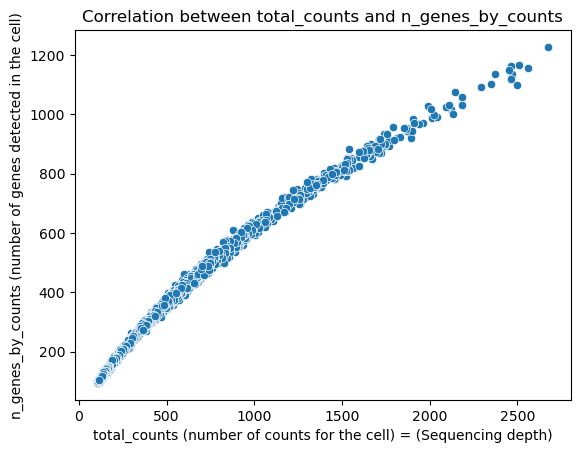

In [50]:
# correlation between n_genes_by_counts and total_counts

sns.scatterplot(x="total_counts", y="n_genes_by_counts", data=data_all.obs)
# add title and x and y labels
plt.title("Correlation between total_counts and n_genes_by_counts")
plt.xlabel("total_counts (number of counts for the cell) = (Sequencing depth)")
plt.ylabel("n_genes_by_counts (number of genes detected in the cell)")
plt.show()

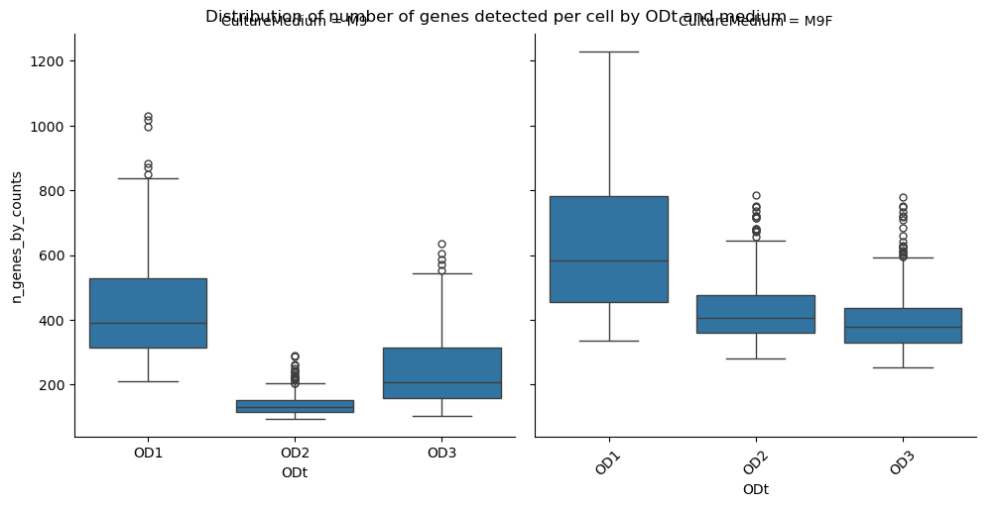

In [51]:
# correlation between OD_measured and n_genes_by_counts
# Create a boxplot of n_genes_by_counts grouped by OD_measured, split by culture medium
sns.catplot(
    x="ODt", y="n_genes_by_counts", col="CultureMedium", data=data_all.obs, kind="box"
)
plt.xticks(rotation=45)  # Rotate x-axis labels by 45 degrees
plt.suptitle("Distribution of number of genes detected per cell by ODt and medium")
plt.show()

In [52]:
# # Correlation between OD measured and mean number of genes detected, split by culture medium
# g = sns.lmplot(
#     data=data_all.obs,
#     x="OD_measured",
#     y="n_genes_by_counts",
#     col="CultureMedium",
#     scatter=True,
#     ci=95,
#     height=5,
#     aspect=0.8
# )

# plt.suptitle("Correlation between OD measured and number of genes detected by medium")
# g.set_axis_labels("OD measured", "Number of genes detected")
# plt.show()

In [53]:
data_all.obs.groupby("OD")[
    "n_genes_by_counts"
].describe()  # number of genes detected per cell, grouped by OD condition

,count,mean,std,min,25%,50%,75%,max
OD,,,,,,,,
M9F_A_OD1,161.0,600.788820,77.640148,488.0,545.00,582.0,634.00,852.0
M9F_A_OD2,160.0,447.137500,89.150039,339.0,385.00,421.0,476.50,748.0
M9F_A_OD3,160.0,458.037500,82.863902,356.0,398.75,437.5,480.25,752.0
M9F_B_OD1,161.0,859.385093,113.056074,713.0,777.00,820.0,914.00,1227.0
M9F_B_OD2,156.0,446.583333,83.821928,325.0,383.00,426.5,503.00,784.0
M9F_B_OD3,164.0,377.652439,57.597141,298.0,336.50,366.0,400.00,615.0
M9F_C_OD1,163.0,421.699387,62.009073,336.0,368.50,412.0,456.50,627.0
M9F_C_OD2,164.0,383.268293,83.488223,280.0,322.00,350.0,425.50,671.0
M9F_C_OD3,159.0,348.000000,82.655377,252.0,297.00,322.0,368.00,779.0


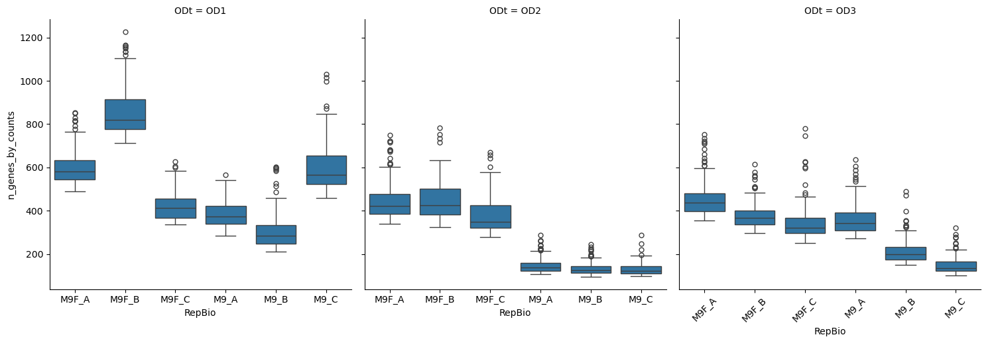

In [54]:
# Create a boxplot of n_genes_by_counts grouped by OD, split by culture medium
sns.catplot(
    x="RepBio",
    y="n_genes_by_counts",  # hue="RepBio_suffix",
    col="ODt",
    data=data_all.obs,
    kind="box",
)
plt.xticks(rotation=45)  # Rotate x-axis labels by 45 degrees
plt.show()


# do a sns boxplot of the pct_counts_in_top_500_genes grouped by OD

In [55]:
data_all.obs.groupby("OD")[
    "total_counts"
].describe()  # number of genes detected per cell, grouped by OD condition

,count,mean,std,min,25%,50%,75%,max
OD,,,,,,,,
M9F_A_OD1,161.0,975.453416,178.510397,765.0,857.00,921.0,1024.00,1673.0
M9F_A_OD2,160.0,656.768750,181.176214,460.0,531.75,594.5,701.25,1318.0
M9F_A_OD3,160.0,676.875000,167.217057,490.0,563.75,630.5,706.00,1361.0
M9F_B_OD1,161.0,1624.515528,326.274848,1230.0,1366.00,1535.0,1746.00,2677.0
M9F_B_OD2,156.0,655.852564,168.607496,457.0,537.00,611.5,753.75,1444.0
M9F_B_OD3,164.0,527.804878,107.900367,405.0,449.75,504.0,567.25,1027.0
M9F_C_OD1,163.0,610.822086,116.364737,464.0,518.50,580.0,680.00,1036.0
M9F_C_OD2,164.0,539.969512,155.380768,371.0,428.00,472.0,610.25,1077.0
M9F_C_OD3,159.0,477.735849,158.425778,332.0,387.50,424.0,509.50,1410.0


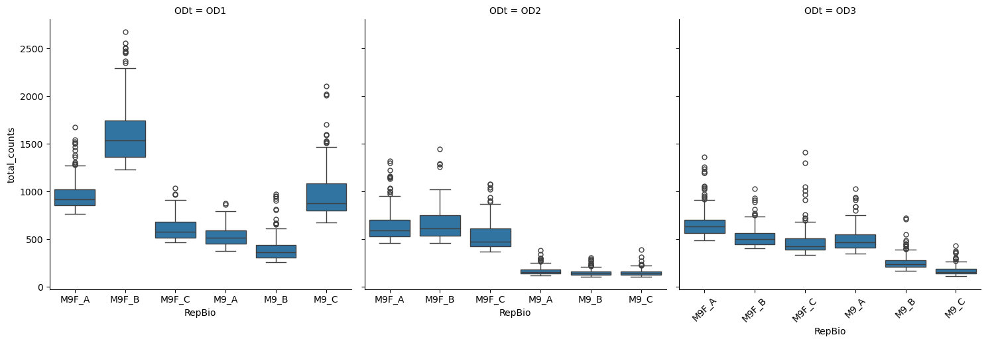

In [56]:
# Create a boxplot of total counts grouped by OD, split by culture medium
sns.catplot(
    x="RepBio",
    y="total_counts",  # hue="RepBio_suffix",
    col="ODt",
    data=data_all.obs,
    kind="box",
)
plt.xticks(rotation=45)  # Rotate x-axis labels by 45 degrees
plt.show()


# do a sns boxplot of the pct_counts_in_top_500_genes grouped by OD

In [57]:
data_all.obs.groupby("OD")["pct_counts_in_top_50_genes"].describe()

,count,mean,std,min,25%,50%,75%,max
OD,,,,,,,,
M9F_A_OD1,161.0,29.042288,1.319232,24.551570,28.000000,29.139073,29.988331,32.810458
M9F_A_OD2,160.0,30.721493,1.615363,26.079447,29.525371,30.545742,31.763884,35.247525
M9F_A_OD3,160.0,30.349362,1.844179,25.284738,29.062509,30.268717,31.444772,36.575875
M9F_B_OD1,161.0,27.311468,1.056875,24.850657,26.709402,27.305218,27.936963,30.174731
M9F_B_OD2,156.0,30.644761,1.971932,25.796426,29.228632,30.301294,31.971154,35.667396
M9F_B_OD3,164.0,32.024937,2.004597,26.333333,30.710917,31.996344,33.365201,36.385542
M9F_C_OD1,163.0,31.307926,1.856593,27.799228,29.914530,31.211499,32.611301,36.400000
M9F_C_OD2,164.0,32.226424,2.417956,26.418605,30.434896,32.236083,33.906907,37.467018
M9F_C_OD3,159.0,33.195595,2.633163,26.737589,31.528906,33.415842,35.000000,39.736842


In [58]:
data_all.obs.groupby("OD")["pct_counts_in_top_100_genes"].describe()

,count,mean,std,min,25%,50%,75%,max
OD,,,,,,,,
M9F_A_OD1,161.0,41.950689,1.646061,37.443946,40.917969,42.011278,42.985843,46.405229
M9F_A_OD2,160.0,45.376969,2.274748,38.428325,43.840099,45.629434,47.152676,50.174825
M9F_A_OD3,160.0,45.165809,2.621965,37.813212,43.648043,45.484122,46.941226,51.145038
M9F_B_OD1,161.0,39.321962,1.281388,36.159880,38.447867,39.214424,40.106545,42.460615
M9F_B_OD2,156.0,45.357333,2.690259,38.461538,43.364585,45.251971,47.497968,51.195219
M9F_B_OD3,164.0,46.987755,2.229142,40.000000,45.946711,47.020037,48.301280,51.670379
M9F_C_OD1,163.0,46.291711,2.336520,40.637066,44.632190,46.492986,48.047602,51.962617
M9F_C_OD2,164.0,46.869313,2.723326,39.162791,45.066543,46.915257,48.679487,52.506596
M9F_C_OD3,159.0,47.774801,2.541221,39.193382,46.619876,48.000000,49.289084,55.000000


In [59]:
data_all.obs.groupby("OD")["pct_counts_in_top_500_genes"].describe()

,count,mean,std,min,25%,50%,75%,max
OD,,,,,,,,
M9F_A_OD1,161.0,90.573215,5.430777,77.172503,86.952288,90.989011,94.699647,100.000000
M9F_A_OD2,160.0,98.186167,4.462508,81.183612,100.000000,100.000000,100.000000,100.000000
M9F_A_OD3,160.0,98.153681,4.436936,81.443299,100.000000,100.000000,100.000000,100.000000
M9F_B_OD1,161.0,78.309112,2.467377,72.842734,76.606061,78.469242,79.985704,83.163665
M9F_B_OD2,156.0,98.569313,3.648446,80.332410,99.597853,100.000000,100.000000,100.000000
M9F_B_OD3,164.0,99.739374,1.381454,88.802337,100.000000,100.000000,100.000000,100.000000
M9F_C_OD1,163.0,99.431804,2.062572,87.741313,100.000000,100.000000,100.000000,100.000000
M9F_C_OD2,164.0,99.307033,2.531270,84.122563,100.000000,100.000000,100.000000,100.000000
M9F_C_OD3,159.0,99.452000,2.798640,80.212766,100.000000,100.000000,100.000000,100.000000


pct_counts_in_top_500_genes - Explication
Cette métrique représente le pourcentage de comptes (reads) qui proviennent des 500 gènes les plus exprimés dans chaque cellule.
Comment c'est calculé :
Pour chaque cellule, on trie tous les gènes par ordre décroissant de leur expression (nombre de comptes)
On prend les 500 gènes les plus exprimés
On calcule le pourcentage que représentent ces 500 gènes par rapport au total des comptes de la cellule

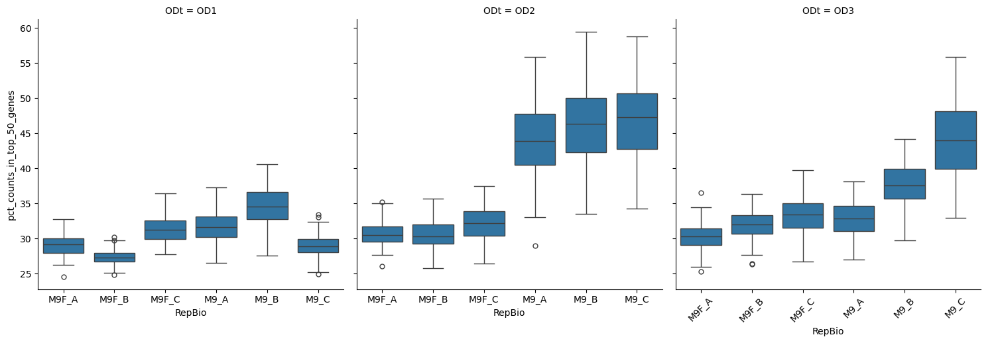

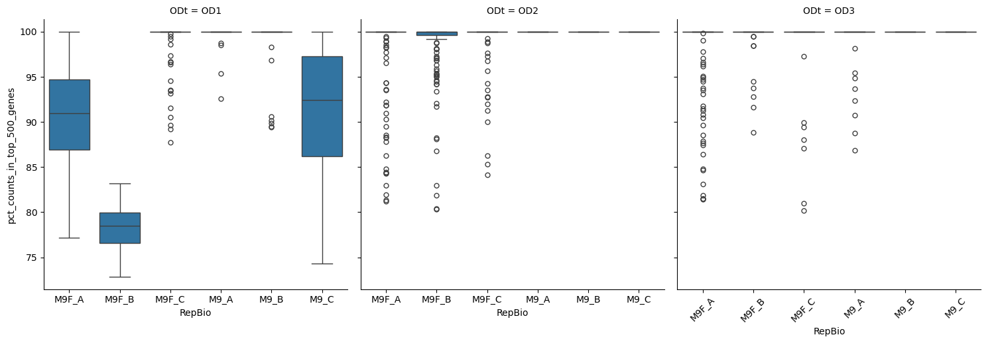

In [60]:
# Create a boxplot of pct_counts_in_top_500_genes grouped by OD, split by culture medium
sns.catplot(
    x="RepBio",
    y="pct_counts_in_top_50_genes",  # hue="RepBio_suffix",
    col="ODt",
    data=data_all.obs,
    kind="box",
)
plt.xticks(rotation=45)  # Rotate x-axis labels by 45 degrees
plt.show()


# Create a boxplot of pct_counts_in_top_500_genes grouped by OD, split by culture medium
sns.catplot(
    x="RepBio",
    y="pct_counts_in_top_500_genes",  # hue="RepBio_suffix",
    col="ODt",
    data=data_all.obs,
    kind="box",
)
plt.xticks(rotation=45)  # Rotate x-axis labels by 45 degrees
plt.show()

In [61]:
data_all.var.head()

,feature_id,gene_id,feature_type,Accession,Begin,End,Chromosome,Orientation,Name,Symbol,...,total_counts,log1p_total_counts,n_cells,gene_pass_union_OD_5pct,gene_pass_intersection_OD_5pct,gene_pass_union_OD_10pct,gene_pass_intersection_OD_10pct,gene_pass_union_OD_15pct,gene_pass_intersection_OD_15pct,original_gene_ids
final_gene_name,,,,,,,,,,,,,,,,,,,,,
recC,gene-QLH64_00030,QLH64-00030,Gene Expression,CP125961.1,5894,9346,unknown,plus,exodeoxyribonuclease V subunit gamma,recC,...,158,5.068904,156,True,False,True,False,False,False,QLH64-00030
recB,gene-QLH64_00035,QLH64-00035,Gene Expression,CP125961.1,9343,13032,unknown,plus,exodeoxyribonuclease V subunit beta,recB,...,116,4.762174,119,True,False,True,False,False,False,QLH64-00035
recD,gene-QLH64_00040,QLH64-00040,Gene Expression,CP125961.1,13029,15125,unknown,plus,exodeoxyribonuclease V subunit alpha,recD,...,111,4.718499,109,True,False,False,False,False,False,QLH64-00040
QLH64-00045,gene-QLH64_00045,QLH64-00045,Gene Expression,CP125961.1,15265,15840,chromosome,plus,YfiR family protein,NaN,...,56,4.043051,58,False,False,False,False,False,False,QLH64-00045
QLH64-00050,gene-QLH64_00050,QLH64-00050,Gene Expression,CP125961.1,15837,17105,chromosome,plus,diguanylate cyclase,NaN,...,45,3.828641,44,True,False,False,False,False,False,QLH64-00050


In [62]:
data_all.var[
    "n_cells_by_counts"
].describe()  # est le nombre de ceelules dans lequel on detecte ce gene

count    5509.000000
mean      198.706843
std       353.717731
min         4.000000
25%        28.000000
50%        70.000000
75%       191.000000
max      2852.000000
Name: n_cells_by_counts, dtype: float64

In [63]:
data_all.var[
    "n_cells_by_counts"
].describe()  # est le nombre de ceelules dans lequel on detecte ce gene

count    5509.000000
mean      198.706843
std       353.717731
min         4.000000
25%        28.000000
50%        70.000000
75%       191.000000
max      2852.000000
Name: n_cells_by_counts, dtype: float64

max = 2784 cells possèdes le meme gene 
min =3 ; le gène le moins retrouvé est present dans seulement 3 cellules 

In [64]:
# Display genes sorted by total counts in descending order, showing only total_counts and final_gene_names columns
data_all.var.sort_values(by="total_counts", ascending=False)[["total_counts", "Name"]]

,total_counts,Name
final_gene_name,,
QLH64-04320,25989,flagellin
QLH64-05400,19589,OmpA family protein
QLH64-13710,16061,thiolase family protein
QLH64-13705,15930,hydroxymethylglutaryl-CoA synthase
QLH64-13720,14539,type III polyketide synthase
...,...,...
QLH64-04970,4,hypothetical protein
QLH64-11980,4,pentapeptide repeat-containing protein
QLH64-24870,4,NorM family multidrug efflux MATE transporter


In [65]:
top_100_gene_count = data_all.var.sort_values(by="total_counts", ascending=False)[
    ["total_counts", "Name"]
].head(100)
print(top_100_gene_count)

                 total_counts                                           Name
final_gene_name                                                             
QLH64-04320             25989                                      flagellin
QLH64-05400             19589                            OmpA family protein
QLH64-13710             16061                        thiolase family protein
QLH64-13705             15930             hydroxymethylglutaryl-CoA synthase
QLH64-13720             14539                   type III polyketide synthase
...                       ...                                            ...
QLH64-02835              2833                 ornithine carbamoyltransferase
QLH64-12155              2831                            chlorinating enzyme
QLH64-20660              2810              DUF4198 domain-containing protein
aceF                     2805  dihydrolipoyllysine-residue acetyltransferase
rpsS                     2793                      30S ribosomal protein S19

In [66]:
# Display genes sorted by total counts in descending order, showing only total_counts and final_gene_names columns : probablement les house keeping genes

cell_housekeeping_genes = data_all.var.sort_values(
    by="n_cells_by_counts", ascending=False
)[["n_cells_by_counts", "Name", "total_counts"]]

print(cell_housekeeping_genes)

                 n_cells_by_counts  \
final_gene_name                      
QLH64-04320                   2852   
QLH64-05400                   2795   
QLH64-13710                   2747   
QLH64-13705                   2737   
QLH64-13720                   2707   
...                            ...   
QLH64-24870                      4   
QLH64-15365                      4   
QLH64-11980                      4   
QLH64-04970                      4   
QLH64-07440                      4   

                                                          Name  total_counts  
final_gene_name                                                               
QLH64-04320                                          flagellin         25989  
QLH64-05400                                OmpA family protein         19589  
QLH64-13710                            thiolase family protein         16061  
QLH64-13705                 hydroxymethylglutaryl-CoA synthase         15930  
QLH64-13720                    

In [67]:
pip install  adjustText

Note: you may need to restart the kernel to use updated packages.


                 n_cells_by_counts  \
final_gene_name                      
QLH64-04320                   2852   
QLH64-05400                   2795   
QLH64-13710                   2747   
QLH64-13705                   2737   
QLH64-13720                   2707   
...                            ...   
QLH64-20660                   1605   
QLH64-12185                   1601   
rpsS                          1601   
pyk_2                         1601   
aceF                          1585   

                                                             Name  \
final_gene_name                                                     
QLH64-04320                                             flagellin   
QLH64-05400                                   OmpA family protein   
QLH64-13710                               thiolase family protein   
QLH64-13705                    hydroxymethylglutaryl-CoA synthase   
QLH64-13720                          type III polyketide synthase   
...                   

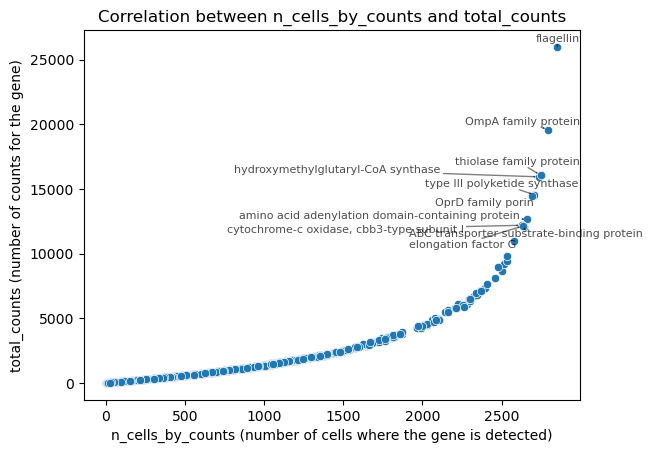

In [68]:
# Display genes sorted by total counts in descending order, showing only total_counts and final_gene_names columns : probablement les house keeping genes

top_100_ncells = data_all.var.sort_values(by="n_cells_by_counts", ascending=False)[
    ["n_cells_by_counts", "Name", "total_counts"]
].head(100)

print(top_100_ncells)

# correlation between n_cells_by_counts and total_counts

sns.scatterplot(x="n_cells_by_counts", y="total_counts", data=data_all.var)
# add title and x and y labels
plt.title("Correlation between n_cells_by_counts and total_counts")
plt.xlabel("n_cells_by_counts (number of cells where the gene is detected)")
plt.ylabel("total_counts (number of counts for the gene)")
# add label (final_gene_name) for the top 10 genes using adjustText package
# First install adjustText if not already installed:
# !pip install adjustText

from adjustText import adjust_text

texts = []
for i, row in top_100_ncells.head(10).iterrows():
    texts.append(
        plt.text(
            row["n_cells_by_counts"],
            row["total_counts"],
            row["Name"],
            fontsize=8,
            alpha=0.7,
        )
    )

# Adjust text positions to avoid overlapping
adjust_text(texts, arrowprops=dict(arrowstyle="->", color="black", alpha=0.5))
plt.show()

In [69]:
# Display top 10 genes by number of cells expressing them
data_all.var.sort_values(by="n_cells_by_counts", ascending=False).head(10)[
    ["Name", "n_cells_by_counts"]
]

# Get vector of top 10 gene names
top_10_genes = (
    data_all.var.sort_values(by="n_cells_by_counts", ascending=False)
    .head(10)["final_gene_name"]
    .values
)
print("Top 10 most expressed genes:", top_10_genes)

# Calculate sum of counts for top 10 genes by OD
top_10_counts_by_od = data_all[:, top_10_genes].X.toarray().sum(axis=1)
top_10_counts_by_od = pd.DataFrame(
    {"top_10_counts": top_10_counts_by_od, "OD": data_all.obs["OD"]}
)

# Group and calculate statistics by OD
top_10_stats = top_10_counts_by_od.groupby("OD")["top_10_counts"].agg(
    ["mean", "std", "count"]
)
print("\nStatistics of top 10 gene counts by OD:")
print(top_10_stats)

# Same analysis but only with the first gene in the list
first_gene = top_10_genes[0]
first_gene_counts = data_all[:, first_gene].X.toarray().flatten()
first_gene_counts_by_od = pd.DataFrame(
    {"first_gene_counts": first_gene_counts, "OD": data_all.obs["OD"]}
)

# Group and calculate statistics by OD
first_gene_stats = first_gene_counts_by_od.groupby("OD")["first_gene_counts"].agg(
    ["mean", "std", "count"]
)
print(f"\nStatistics of {first_gene} counts by OD:")
print(first_gene_stats)
# Calculate descriptive statistics for the first gene by OD
first_gene_stats_detailed = first_gene_counts_by_od.groupby("OD")[
    "first_gene_counts"
].describe()
print(f"\nDetailed statistics of {first_gene} counts by OD:")
print(first_gene_stats_detailed)

Top 10 most expressed genes: ['QLH64-04320' 'QLH64-05400' 'QLH64-13710' 'QLH64-13705' 'QLH64-13720'
 'QLH64-19225' 'QLH64-00425' 'QLH64-00845' 'fusA' 'ccoN_2']

Statistics of top 10 gene counts by OD:
                 mean        std  count
OD                                     
M9F_A_OD1   93.751553  19.233445    161
M9F_A_OD2   62.943750  18.206795    160
M9F_A_OD3   63.575000  18.723929    160
M9F_B_OD1  155.062112  32.591159    161
M9F_B_OD2   62.262821  16.623773    156
M9F_B_OD3   50.219512  12.123115    164
M9F_C_OD1   59.018405  12.779455    163
M9F_C_OD2   52.158537  16.789910    164
M9F_C_OD3   45.603774  15.656931    159
M9_A_OD1    50.298780  11.618253    164
M9_A_OD2    16.462500   5.546700    160
M9_A_OD3    48.219512  14.449425    164
M9_B_OD1    38.814815  15.193257    162
M9_B_OD2    14.063694   4.997027    157
M9_B_OD3    24.527950  10.285950    161
M9_C_OD1    93.800000  27.008851    165
M9_C_OD2    14.355422   5.156949    166
M9_C_OD3    16.644578   7.247165    166

In [70]:
# Find the highest UMI count in the entire matrix
# Get the full count matrix
count_matrix = data_all.X.toarray()

# Find the maximum value and its position
max_value = count_matrix.max()
max_pos = np.unravel_index(count_matrix.argmax(), count_matrix.shape)

# Get the corresponding cell and gene names
cell_name = data_all.obs.index[max_pos[0]]
gene_name = data_all.var.index[max_pos[1]]

print("Highest UMI count in the matrix:")
print(f"Value: {max_value}")
print(f"\nCell: {cell_name}")
print(f"Gene: {gene_name}")

# Get additional info about this gene
gene_info = data_all.var.loc[gene_name]
print("\nGene details:")
print(f"Name: {gene_info['Name']}")
print(f"Feature type: {gene_info['feature_type']}")

Highest UMI count in the matrix:
Value: 51

Cell: TATCAGCA_GACTAGTA_GTGGGTTC
Gene: QLH64-04320

Gene details:
Name: flagellin
Feature type: Gene Expression


In [71]:
# Find the gene with highest intersection across cells
# Get the intersection matrix
intersection_matrix = data_all.X.toarray()

# Calculate the sum for each gene (column)
gene_sums = intersection_matrix.sum(axis=0)

# Get the index of the gene with maximum sum
max_gene_idx = gene_sums.argmax()

# Get the gene name and sum value
max_gene_name = data_all.var.index[max_gene_idx]
max_gene_sum = gene_sums[max_gene_idx]

print(f"Gene with highest total counts across cells:")
print(f"Gene: {max_gene_name}")
print(f"Total counts: {max_gene_sum}")

# Get additional info about this gene
gene_info = data_all.var.loc[max_gene_name]
print("\nGene details:")
print(f"Name: {gene_info['Name']}")
print(f"Number of cells expressing this gene: {gene_info['n_cells_by_counts']}")
print(f"Mean counts per cell: {gene_info['mean_counts']:.2f}")

Gene with highest total counts across cells:
Gene: QLH64-04320
Total counts: 25989

Gene details:
Name: flagellin
Number of cells expressing this gene: 2852
Mean counts per cell: 8.92


In [72]:
# Find max UMI count in one line using scanpy
print(f"Max UMI count: {data_all.X.max()}")
# name of the gene with the max UMI count
print(
    f"Gene with max UMI count: {data_all.var.index[data_all.X.argmax(axis=1).A1.argmax()]}"
)
# name of the cell with the max UMI count
print(
    f"Cell with max UMI count: {data_all.obs.index[data_all.X.argmax(axis=0).A1.argmax()]}"
)

Max UMI count: 51
Gene with max UMI count: QLH64-12950
Cell with max UMI count: CTGAGCCA_CACCTTAC_GGGTAGCG


In [73]:
# Save raw counts into a layer of the anndata
data_all.layers["counts"] = data_all.X.copy()

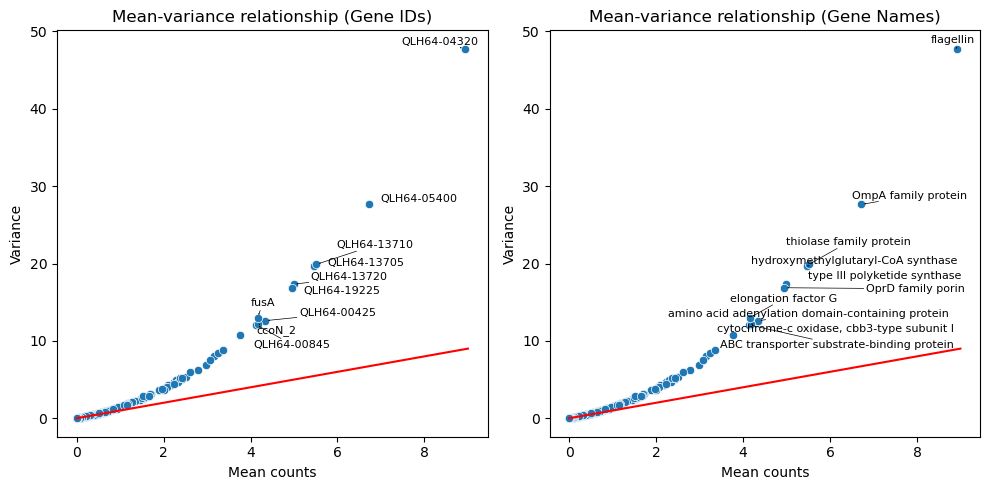

In [74]:
# Calculate variance and mean counts
data_all.var["var_counts"] = np.asarray(np.var(data_all.X.toarray(), axis=0)).squeeze()
data_all.var["mean_counts"] = np.asarray(
    np.mean(data_all.X.toarray(), axis=0)
).squeeze()

# Create figure with two subplots
plt.figure(figsize=(10, 5))

# First plot with gene IDs
plt.subplot(1, 2, 1)
sns.scatterplot(data=data_all.var, x="mean_counts", y="var_counts")

# Add diagonal line
plt.plot(
    [0, np.ceil(np.max(data_all.var["mean_counts"]))],
    [0, np.ceil(np.max(data_all.var["mean_counts"]))],
    color="red",
)

# Get top 10 genes by mean counts
top_10_genes = data_all.var.nlargest(10, "mean_counts")

# Create labels for gene IDs
labels = []
for idx, (gene_name, row) in enumerate(top_10_genes.iterrows(), 1):
    labels.append({"x": row["mean_counts"], "y": row["var_counts"], "text": gene_name})

# Use adjustText to prevent label overlap
texts = [
    plt.text(label["x"], label["y"], label["text"], fontsize=8) for label in labels
]
from adjustText import adjust_text

adjust_text(texts, arrowprops=dict(arrowstyle="->", color="black", lw=0.5))

plt.title("Mean-variance relationship (Gene IDs)")
plt.xlabel("Mean counts")
plt.ylabel("Variance")

# Second plot with gene Names
plt.subplot(1, 2, 2)
sns.scatterplot(data=data_all.var, x="mean_counts", y="var_counts")

# Add diagonal line
plt.plot(
    [0, np.ceil(np.max(data_all.var["mean_counts"]))],
    [0, np.ceil(np.max(data_all.var["mean_counts"]))],
    color="red",
)

# Create labels for gene Names
labels = []
for idx, (gene_name, row) in enumerate(top_10_genes.iterrows(), 1):
    gene_label = row["Name"] if not pd.isna(row["Name"]) else gene_name
    labels.append({"x": row["mean_counts"], "y": row["var_counts"], "text": gene_label})

# Use adjustText to prevent label overlap
texts = [
    plt.text(label["x"], label["y"], label["text"], fontsize=8) for label in labels
]
adjust_text(texts, arrowprops=dict(arrowstyle="->", color="black", lw=0.5))

plt.title("Mean-variance relationship (Gene Names)")
plt.xlabel("Mean counts")
plt.ylabel("Variance")

plt.tight_layout()
plt.show()

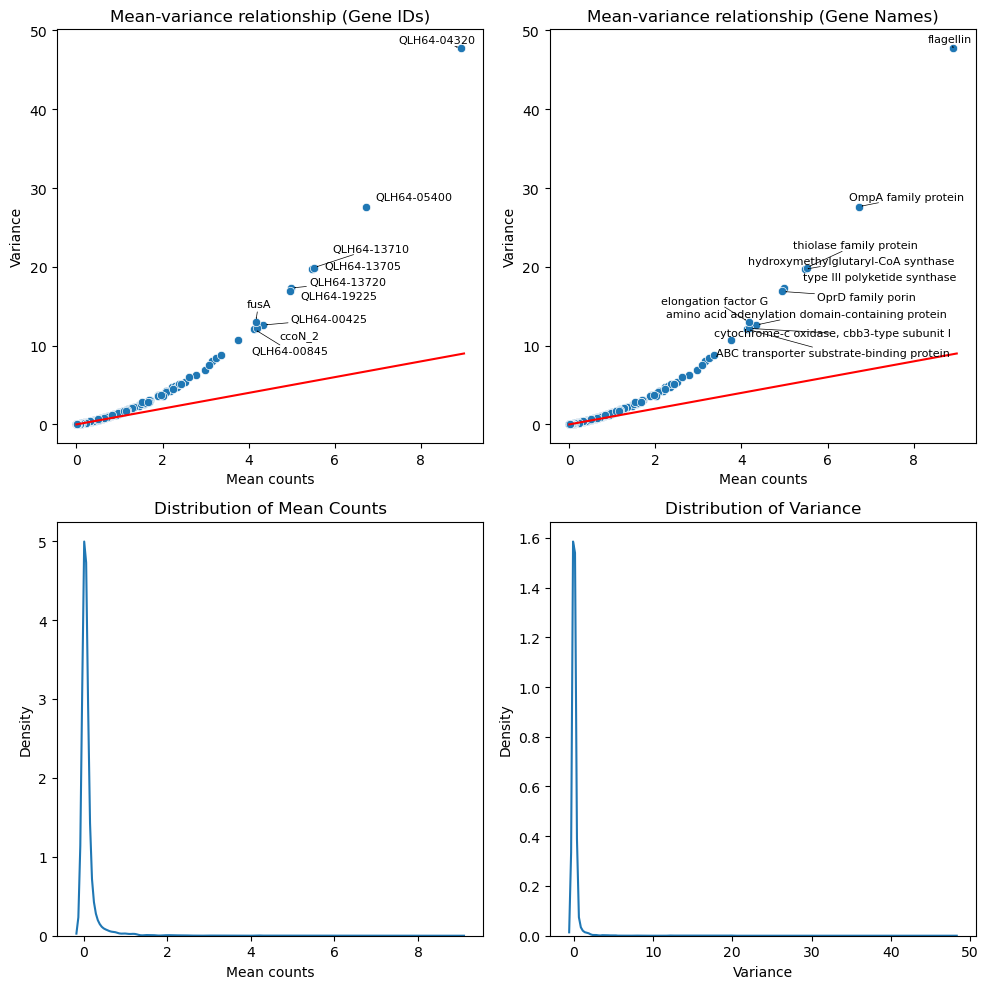

In [75]:
# Calculate variance and mean counts
data_all.var["var_counts"] = np.asarray(np.var(data_all.X.toarray(), axis=0)).squeeze()
data_all.var["mean_counts"] = np.asarray(
    np.mean(data_all.X.toarray(), axis=0)
).squeeze()

# Create figure with subplots - 2 rows, 2 columns
fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(2, 2)

# First scatter plot with gene IDs
ax1 = fig.add_subplot(gs[0, 0])
sns.scatterplot(data=data_all.var, x="mean_counts", y="var_counts", ax=ax1)

# Add diagonal line
ax1.plot(
    [0, np.ceil(np.max(data_all.var["mean_counts"]))],
    [0, np.ceil(np.max(data_all.var["mean_counts"]))],
    color="red",
)

# Get top 10 genes by mean counts
top_10_genes = data_all.var.nlargest(10, "mean_counts")

# Create labels for gene IDs
labels = []
for idx, (gene_name, row) in enumerate(top_10_genes.iterrows(), 1):
    labels.append({"x": row["mean_counts"], "y": row["var_counts"], "text": gene_name})

# Use adjustText to prevent label overlap
texts = [
    ax1.text(label["x"], label["y"], label["text"], fontsize=8) for label in labels
]
adjust_text(texts, arrowprops=dict(arrowstyle="->", color="black", lw=0.5))

ax1.set_title("Mean-variance relationship (Gene IDs)")
ax1.set_xlabel("Mean counts")
ax1.set_ylabel("Variance")

# Second scatter plot with gene Names
ax2 = fig.add_subplot(gs[0, 1])
sns.scatterplot(data=data_all.var, x="mean_counts", y="var_counts", ax=ax2)

# Add diagonal line
ax2.plot(
    [0, np.ceil(np.max(data_all.var["mean_counts"]))],
    [0, np.ceil(np.max(data_all.var["mean_counts"]))],
    color="red",
)

# Create labels for gene Names
labels = []
for idx, (gene_name, row) in enumerate(top_10_genes.iterrows(), 1):
    gene_label = row["Name"] if not pd.isna(row["Name"]) else gene_name
    labels.append({"x": row["mean_counts"], "y": row["var_counts"], "text": gene_label})

# Use adjustText to prevent label overlap
texts = [
    ax2.text(label["x"], label["y"], label["text"], fontsize=8) for label in labels
]
adjust_text(texts, arrowprops=dict(arrowstyle="->", color="black", lw=0.5))

ax2.set_title("Mean-variance relationship (Gene Names)")
ax2.set_xlabel("Mean counts")
ax2.set_ylabel("Variance")

# Add density plots below
# Mean counts density
ax3 = fig.add_subplot(gs[1, 0])
sns.kdeplot(data=data_all.var["mean_counts"], ax=ax3)
ax3.set_title("Distribution of Mean Counts")
ax3.set_xlabel("Mean counts")
ax3.set_ylabel("Density")

# Variance density
ax4 = fig.add_subplot(gs[1, 1])
sns.kdeplot(data=data_all.var["var_counts"], ax=ax4)
ax4.set_title("Distribution of Variance")
ax4.set_xlabel("Variance")
ax4.set_ylabel("Density")

plt.tight_layout()
plt.show()

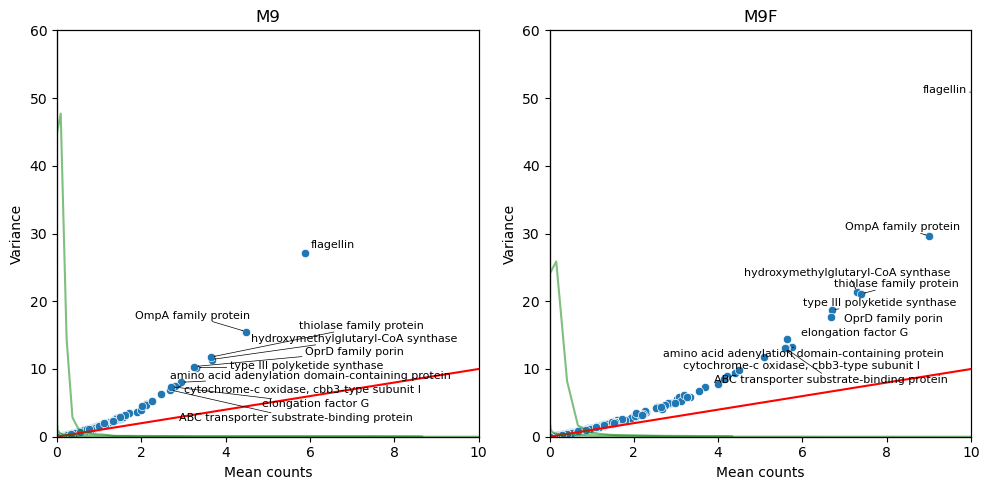

In [76]:
# Import required library
from scipy import stats

# Calculate variance and mean counts
data_all.var["var_counts"] = np.asarray(np.var(data_all.X.toarray(), axis=0)).squeeze()
data_all.var["mean_counts"] = np.asarray(
    np.mean(data_all.X.toarray(), axis=0)
).squeeze()

# Create figure with subplots - one per culture medium
n_media = len(data_all.obs["CultureMedium"].unique())
fig, axes = plt.subplots(1, n_media, figsize=(10 * n_media / 2, 5))

# Set fixed axis limits
fixed_max_mean = 10  # Fixed x-axis limit
fixed_max_var = 60  # Fixed y-axis limit

# Find global max density for consistent scaling
max_density_var = 0
max_density_mean = 0
for medium in sorted(data_all.obs["CultureMedium"].unique()):
    medium_cells = data_all.obs["CultureMedium"] == medium
    medium_data = data_all[medium_cells]

    medium_var = np.asarray(np.var(medium_data.X.toarray(), axis=0)).squeeze()
    medium_mean = np.asarray(np.mean(medium_data.X.toarray(), axis=0)).squeeze()

    # Calculate KDE for variance and mean
    kde_var = stats.gaussian_kde(medium_var)
    kde_mean = stats.gaussian_kde(medium_mean)

    # Get max density values
    max_density_var = max(max_density_var, kde_var(medium_var).max())
    max_density_mean = max(max_density_mean, kde_mean(medium_mean).max())

for idx, medium in enumerate(sorted(data_all.obs["CultureMedium"].unique())):
    # Filter data for current medium
    medium_cells = data_all.obs["CultureMedium"] == medium
    medium_data = data_all[medium_cells]

    # Calculate medium-specific variance and mean counts
    medium_var = np.asarray(np.var(medium_data.X.toarray(), axis=0)).squeeze()
    medium_mean = np.asarray(np.mean(medium_data.X.toarray(), axis=0)).squeeze()

    # Create temporary dataframe for plotting
    plot_df = pd.DataFrame(
        {
            "mean_counts": medium_mean,
            "var_counts": medium_var,
            "Name": data_all.var["Name"],
        },
        index=data_all.var.index,
    )

    # Create scatter plot
    sns.scatterplot(data=plot_df, x="mean_counts", y="var_counts", ax=axes[idx])

    # Add density plots on margins with consistent scaling
    # Top margin density plot
    ax_top = axes[idx].twinx()
    sns.kdeplot(data=plot_df["var_counts"], ax=ax_top, color="green", alpha=0.5)
    ax_top.set_ylim(0, max_density_var * 1.1)  # Add 10% padding
    ax_top.spines["right"].set_visible(False)
    ax_top.set_ylabel("")
    ax_top.set_yticks([])

    # Right margin density plot
    ax_right = axes[idx].twiny()
    sns.kdeplot(
        data=plot_df["mean_counts"],
        ax=ax_right,
        color="green",
        alpha=0.5,
        vertical=True,
    )
    ax_right.set_xlim(0, max_density_mean * 1.1)  # Add 10% padding
    ax_right.spines["top"].set_visible(False)
    ax_right.set_xlabel("")
    ax_right.set_xticks([])

    # Add diagonal line
    axes[idx].plot(
        [0, fixed_max_mean],
        [0, fixed_max_mean],
        color="red",
    )

    # Set fixed axis limits
    axes[idx].set_xlim(0, fixed_max_mean)
    axes[idx].set_ylim(0, fixed_max_var)

    # Get top 10 genes by mean counts for this medium
    top_10_genes = plot_df.nlargest(10, "mean_counts")

    # Create labels for gene Names
    labels = []
    for _, (gene_name, row) in enumerate(top_10_genes.iterrows(), 1):
        gene_label = row["Name"] if not pd.isna(row["Name"]) else gene_name
        labels.append(
            {"x": row["mean_counts"], "y": row["var_counts"], "text": gene_label}
        )

    # Use adjustText to prevent label overlap
    texts = [
        axes[idx].text(label["x"], label["y"], label["text"], fontsize=8)
        for label in labels
    ]
    adjust_text(texts, arrowprops=dict(arrowstyle="->", color="black", lw=0.5))

    axes[idx].set_title(f"{medium}")
    axes[idx].set_xlabel("Mean counts")
    axes[idx].set_ylabel("Variance")

plt.tight_layout()
plt.show()

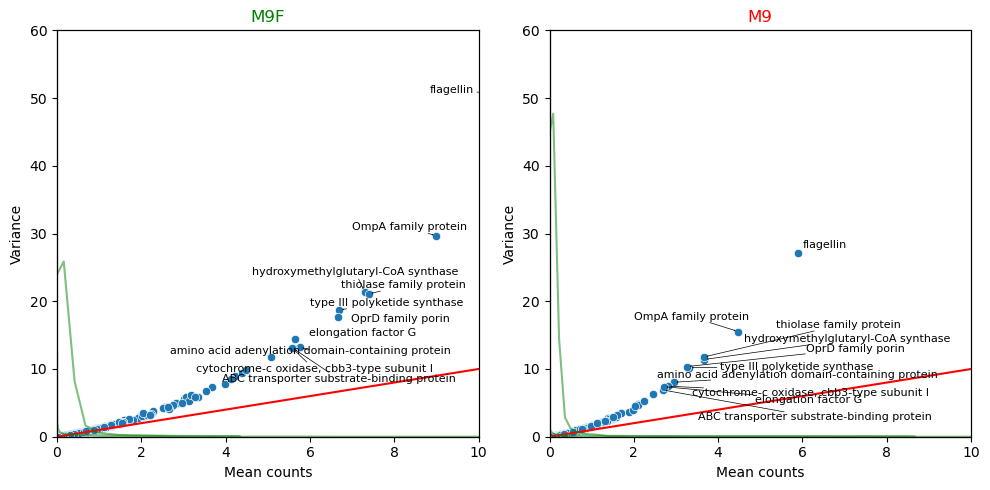

In [77]:
# Import required library
from scipy import stats

# Calculate variance and mean counts
data_all.var["var_counts"] = np.asarray(np.var(data_all.X.toarray(), axis=0)).squeeze()
data_all.var["mean_counts"] = np.asarray(
    np.mean(data_all.X.toarray(), axis=0)
).squeeze()

# Create figure with subplots - one per culture medium
n_media = len(data_all.obs["CultureMedium"].unique())
fig, axes = plt.subplots(1, n_media, figsize=(10 * n_media / 2, 5))

# Set fixed axis limits
fixed_max_mean = 10  # Fixed x-axis limit
fixed_max_var = 60  # Fixed y-axis limit

# Find global max density for consistent scaling
max_density_var = 0
max_density_mean = 0

# Sort media to have M9F first, then M9
media_order = sorted(
    data_all.obs["CultureMedium"].unique(),
    key=lambda x: "0" if x.startswith("M9F") else "1",
)

for medium in media_order:
    medium_cells = data_all.obs["CultureMedium"] == medium
    medium_data = data_all[medium_cells]

    medium_var = np.asarray(np.var(medium_data.X.toarray(), axis=0)).squeeze()
    medium_mean = np.asarray(np.mean(medium_data.X.toarray(), axis=0)).squeeze()

    # Calculate KDE for variance and mean
    kde_var = stats.gaussian_kde(medium_var)
    kde_mean = stats.gaussian_kde(medium_mean)

    # Get max density values
    max_density_var = max(max_density_var, kde_var(medium_var).max())
    max_density_mean = max(max_density_mean, kde_mean(medium_mean).max())

for idx, medium in enumerate(media_order):
    # Filter data for current medium
    medium_cells = data_all.obs["CultureMedium"] == medium
    medium_data = data_all[medium_cells]

    # Calculate medium-specific variance and mean counts
    medium_var = np.asarray(np.var(medium_data.X.toarray(), axis=0)).squeeze()
    medium_mean = np.asarray(np.mean(medium_data.X.toarray(), axis=0)).squeeze()

    # Create temporary dataframe for plotting
    plot_df = pd.DataFrame(
        {
            "mean_counts": medium_mean,
            "var_counts": medium_var,
            "Name": data_all.var["Name"],
        },
        index=data_all.var.index,
    )

    # Create scatter plot
    sns.scatterplot(data=plot_df, x="mean_counts", y="var_counts", ax=axes[idx])

    # Add density plots on margins with consistent scaling
    # Top margin density plot
    ax_top = axes[idx].twinx()
    sns.kdeplot(data=plot_df["var_counts"], ax=ax_top, color="green", alpha=0.5)
    ax_top.set_ylim(0, max_density_var * 1.1)  # Add 10% padding
    ax_top.spines["right"].set_visible(False)
    ax_top.set_ylabel("")
    ax_top.set_yticks([])

    # Right margin density plot
    ax_right = axes[idx].twiny()
    sns.kdeplot(
        data=plot_df["mean_counts"],
        ax=ax_right,
        color="green",
        alpha=0.5,
        vertical=True,
    )
    ax_right.set_xlim(0, max_density_mean * 1.1)  # Add 10% padding
    ax_right.spines["top"].set_visible(False)
    ax_right.set_xlabel("")
    ax_right.set_xticks([])

    # Add diagonal line
    axes[idx].plot(
        [0, fixed_max_mean],
        [0, fixed_max_mean],
        color="red",
    )

    # Set fixed axis limits
    axes[idx].set_xlim(0, fixed_max_mean)
    axes[idx].set_ylim(0, fixed_max_var)

    # Get top 10 genes by mean counts for this medium
    top_10_genes = plot_df.nlargest(10, "mean_counts")

    # Create labels for gene Names
    labels = []
    for _, (gene_name, row) in enumerate(top_10_genes.iterrows(), 1):
        gene_label = row["Name"] if not pd.isna(row["Name"]) else gene_name
        labels.append(
            {"x": row["mean_counts"], "y": row["var_counts"], "text": gene_label}
        )

    # Use adjustText to prevent label overlap
    texts = [
        axes[idx].text(label["x"], label["y"], label["text"], fontsize=8)
        for label in labels
    ]
    adjust_text(texts, arrowprops=dict(arrowstyle="->", color="black", lw=0.5))

    # Set title and labels with appropriate colors
    if medium.startswith("M9F"):
        axes[idx].set_title(f"{medium}", color="green")
    else:
        axes[idx].set_title(f"{medium}", color="red")
    axes[idx].set_xlabel("Mean counts")
    axes[idx].set_ylabel("Variance")

plt.tight_layout()
plt.show()

🎯 En biologie (ex. scRNA-seq) :
	•	Un gène peut avoir une moyenne élevée mais une variance faible (il est fortement exprimé mais uniformément dans toutes les cellules).
	•	Un gène peut avoir une moyenne faible mais une variance élevée (il est rarement exprimé, mais de manière très hétérogène).

👉 C’est pourquoi la variance est souvent utilisée pour identifier les gènes les plus variables entre cellules (souvent biologiquement intéressants).


🔬 Oui, si la profondeur de séquençage est faible :

👉 alors le nombre de counts par gène sera faible,
👉 et donc la variance aussi sera sous-estimée,
👉 même si biologiquement, l’expression du gène varie entre cellules.

⸻

⚠️ Pourquoi ?

Parce que le comptage en single-cell est bruité et parcellaire :
	•	Un gène peut être biologiquement exprimé dans certaines cellules,
	•	Mais ne pas être capturé/séquencé → dropout (zéro artificiel),
	•	Ce qui écrase à la fois la moyenne ET la variance.

⸻

📊 Conséquence directe :

Tu verras souvent ce pattern en banane dans un graphe Mean vs Variance :
	•	Les gènes peu exprimés (faible mean) ont toujours faible variance,
	•	Les gènes moyennement à fortement exprimés ont variance croissante,
	•	Mais cette relation est en partie technique, pas uniquement biologique.

⸻

🧠 Comment on gère ça ?

Il existe des méthodes pour modéliser la variance attendue selon la moyenne :

📈 On trace :
	•	La variance observée pour chaque gène (ce que tu fais),
	•	Et la variance attendue selon un modèle (souvent Poisson ou NB).



Si tu fais un split des counts pour séparer le signal biologique du bruit technique, il faut connaître la nature de la distribution :
	•	Si les données sont Poisson → le splitting est plus simple (le bruit est symétrique).
	•	Si elles sont NB / surdispersionnées → il faut un modèle plus complexe (bruit variable selon les gènes).

In [78]:
# See if a linear or quadratic relationship fits better
mv_corr_lin = np.corrcoef(data_all.var["mean_counts"], data_all.var["var_counts"])[0, 1]
mv_corr_sq = np.corrcoef(data_all.var["mean_counts"] ** 2, data_all.var["var_counts"])[
    0, 1
]

if mv_corr_sq > mv_corr_lin:
    is_overdispersed = True
else:
    is_overdispersed = False

if is_overdispersed:
    print("Data is overdispersed - use Negative Binomial count splitting")
else:
    print("Data is not overdispersed - use Poisson count splitting")

Data is overdispersed - use Negative Binomial count splitting


In [79]:
data_gene = ut.filter_outliers(data_all, nmads=5, min_cells=500, min_genes=100)
print(data_all.obs.outlier.value_counts())
print(f"Number of cells before filtering: {data_all.n_obs}")
print(f"Number of cells after filtering: {data_gene.n_obs}")
print(f"Number of genes before filtering: {data_all.n_vars}")
print(f"Number of genes after filtering: {data_gene.n_vars}")
data_gene

outlier
False    2913
Name: count, dtype: int64
Number of cells before filtering: 2913
Number of cells after filtering: 2905
Number of genes before filtering: 5509
Number of genes after filtering: 557


AnnData object with n_obs × n_vars = 2905 × 557
    obs: 'barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3', 'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric', 'OD_measured', 'Group', 'n_genes', 'RepTech_suffix', 'RepBio_suffix', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'group', 'outlier'
    var: 'feature_id', 'gene_id', 'feature_type', 'Accession', 'Begin', 'End', 'Chromosome', 'Orientation', 'Name', 'Symbol', 'Gene ID', 'Gene Type', 'Transcripts accession', 'Transcript name', 'Protein accession', 'Protein name', 'Protein length', 'symbol_old', 'locus_tag_old', 'symbol_renamed', 'final_gene_name', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'gene_pass_union_OD_5pct', 'gene_pass_intersection_OD_5pct', 'gene_pass_u

In [80]:
# See if a linear or quadratic relationship fits better
mv_corr_lin = np.corrcoef(data_gene.var["mean_counts"], data_gene.var["var_counts"])[
    0, 1
]
mv_corr_sq = np.corrcoef(
    data_gene.var["mean_counts"] ** 2, data_gene.var["var_counts"]
)[0, 1]

if mv_corr_sq > mv_corr_lin:
    is_overdispersed = True
else:
    is_overdispersed = False

if is_overdispersed:
    print("Data is overdispersed - use Negative Binomial count splitting")
else:
    print("Data is not overdispersed - use Poisson count splitting")

Data is overdispersed - use Negative Binomial count splitting


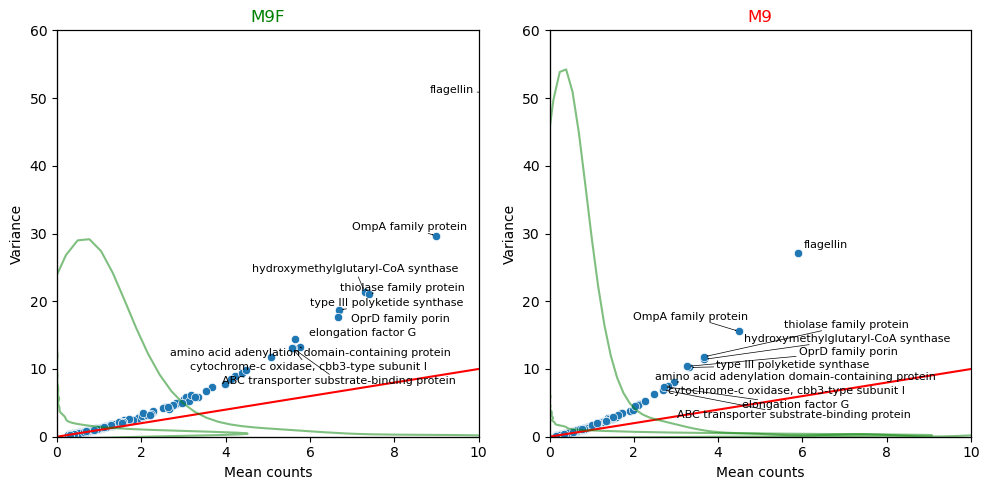

In [81]:
# Import required library
from scipy import stats

# Calculate variance and mean counts
data_gene.var["var_counts"] = np.asarray(
    np.var(data_gene.X.toarray(), axis=0)
).squeeze()
data_gene.var["mean_counts"] = np.asarray(
    np.mean(data_gene.X.toarray(), axis=0)
).squeeze()

# Create figure with subplots - one per culture medium
n_media = len(data_gene.obs["CultureMedium"].unique())
fig, axes = plt.subplots(1, n_media, figsize=(10 * n_media / 2, 5))

# Set fixed axis limits
fixed_max_mean = 10  # Fixed x-axis limit
fixed_max_var = 60  # Fixed y-axis limit

# Find global max density for consistent scaling
max_density_var = 0
max_density_mean = 0

# Sort media to have M9F first, then M9
media_order = sorted(
    data_gene.obs["CultureMedium"].unique(),
    key=lambda x: "0" if x.startswith("M9F") else "1",
)

for medium in media_order:
    medium_cells = data_gene.obs["CultureMedium"] == medium
    medium_data = data_gene[medium_cells]

    medium_var = np.asarray(np.var(medium_data.X.toarray(), axis=0)).squeeze()
    medium_mean = np.asarray(np.mean(medium_data.X.toarray(), axis=0)).squeeze()

    # Calculate KDE for variance and mean
    kde_var = stats.gaussian_kde(medium_var)
    kde_mean = stats.gaussian_kde(medium_mean)

    # Get max density values
    max_density_var = max(max_density_var, kde_var(medium_var).max())
    max_density_mean = max(max_density_mean, kde_mean(medium_mean).max())

for idx, medium in enumerate(media_order):
    # Filter data for current medium
    medium_cells = data_gene.obs["CultureMedium"] == medium
    medium_data = data_gene[medium_cells]

    # Calculate medium-specific variance and mean counts
    medium_var = np.asarray(np.var(medium_data.X.toarray(), axis=0)).squeeze()
    medium_mean = np.asarray(np.mean(medium_data.X.toarray(), axis=0)).squeeze()

    # Create temporary dataframe for plotting
    plot_df = pd.DataFrame(
        {
            "mean_counts": medium_mean,
            "var_counts": medium_var,
            "Name": data_gene.var["Name"],
        },
        index=data_gene.var.index,
    )

    # Create scatter plot
    sns.scatterplot(data=plot_df, x="mean_counts", y="var_counts", ax=axes[idx])

    # Add density plots on margins with consistent scaling
    # Top margin density plot
    ax_top = axes[idx].twinx()
    sns.kdeplot(data=plot_df["var_counts"], ax=ax_top, color="green", alpha=0.5)
    ax_top.set_ylim(0, max_density_var * 1.1)  # Add 10% padding
    ax_top.spines["right"].set_visible(False)
    ax_top.set_ylabel("")
    ax_top.set_yticks([])

    # Right margin density plot
    ax_right = axes[idx].twiny()
    sns.kdeplot(
        data=plot_df["mean_counts"],
        ax=ax_right,
        color="green",
        alpha=0.5,
        vertical=True,
    )
    ax_right.set_xlim(0, max_density_mean * 1.1)  # Add 10% padding
    ax_right.spines["top"].set_visible(False)
    ax_right.set_xlabel("")
    ax_right.set_xticks([])

    # Add diagonal line
    axes[idx].plot(
        [0, fixed_max_mean],
        [0, fixed_max_mean],
        color="red",
    )

    # Set fixed axis limits
    axes[idx].set_xlim(0, fixed_max_mean)
    axes[idx].set_ylim(0, fixed_max_var)

    # Get top 10 genes by mean counts for this medium
    top_10_genes = plot_df.nlargest(10, "mean_counts")

    # Create labels for gene Names
    labels = []
    for _, (gene_name, row) in enumerate(top_10_genes.iterrows(), 1):
        gene_label = row["Name"] if not pd.isna(row["Name"]) else gene_name
        labels.append(
            {"x": row["mean_counts"], "y": row["var_counts"], "text": gene_label}
        )

    # Use adjustText to prevent label overlap
    texts = [
        axes[idx].text(label["x"], label["y"], label["text"], fontsize=8)
        for label in labels
    ]
    adjust_text(texts, arrowprops=dict(arrowstyle="->", color="black", lw=0.5))

    # Set title and labels with appropriate colors
    if medium.startswith("M9F"):
        axes[idx].set_title(f"{medium}", color="green")
    else:
        axes[idx].set_title(f"{medium}", color="red")
    axes[idx].set_xlabel("Mean counts")
    axes[idx].set_ylabel("Variance")

plt.tight_layout()
plt.show()

In [82]:
# %%
# Create a test copy for analysis
test = data_all.copy()

# %%
# Store raw data
test.raw = test.copy()
print(f"Raw data shape: {test.raw.X.shape}")

# %%
# View gene filtering results
list_pass = [
    "gene_pass_union_OD_5pct",
    "gene_pass_intersection_OD_5pct",
    "gene_pass_union_OD_10pct",
    "gene_pass_intersection_OD_10pct",
    "gene_pass_union_OD_15pct",
    "gene_pass_intersection_OD_15pct",
]

# Display first few rows
print("First rows of filtering results:")
print(test.var[list_pass].head())

Raw data shape: (2913, 5509)
First rows of filtering results:
                 gene_pass_union_OD_5pct  gene_pass_intersection_OD_5pct  \
final_gene_name                                                            
recC                                True                           False   
recB                                True                           False   
recD                                True                           False   
QLH64-00045                        False                           False   
QLH64-00050                         True                           False   

                 gene_pass_union_OD_10pct  gene_pass_intersection_OD_10pct  \
final_gene_name                                                              
recC                                 True                            False   
recB                                 True                            False   
recD                                False                            False   
QLH64-00045    

In [83]:
# Display value counts for each threshold
print("\nValue counts for each filtering threshold:")
for col in list_pass:
    print(f"\n{col}:")
    print(test.var[col].value_counts())


Value counts for each filtering threshold:

gene_pass_union_OD_5pct:
gene_pass_union_OD_5pct
True     3565
False    1944
Name: count, dtype: int64

gene_pass_intersection_OD_5pct:
gene_pass_intersection_OD_5pct
False    5012
True      497
Name: count, dtype: int64

gene_pass_union_OD_10pct:
gene_pass_union_OD_10pct
False    3216
True     2293
Name: count, dtype: int64

gene_pass_intersection_OD_10pct:
gene_pass_intersection_OD_10pct
False    5262
True      247
Name: count, dtype: int64

gene_pass_union_OD_15pct:
gene_pass_union_OD_15pct
False    3833
True     1676
Name: count, dtype: int64

gene_pass_intersection_OD_15pct:
gene_pass_intersection_OD_15pct
False    5354
True      155
Name: count, dtype: int64


In [84]:
# %%
# Filter genes based on gene_pass_union_OD_5pct
adata_union = test[:, test.var["gene_pass_union_OD_15pct"] == True].copy()
print(f"Number of genes after filtering: {adata_union.shape[1]}")

Number of genes after filtering: 1676


In [85]:
# %%
# Verify filtering results
print("Verification of filtering:")
print(adata_union.var["gene_pass_union_OD_15pct"].value_counts())

Verification of filtering:
gene_pass_union_OD_15pct
True    1676
Name: count, dtype: int64


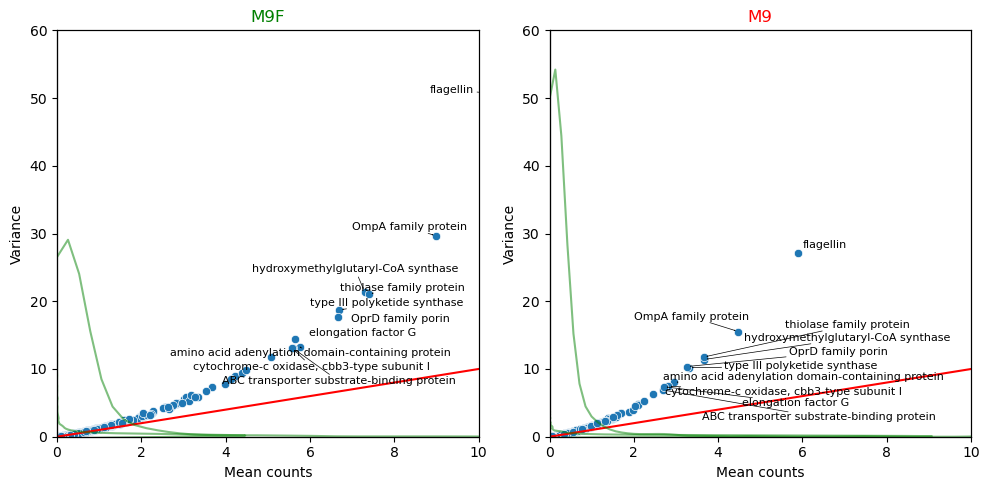

In [86]:
# Import required library
from scipy import stats

# Calculate variance and mean counts
adata_union.var["var_counts"] = np.asarray(
    np.var(adata_union.X.toarray(), axis=0)
).squeeze()
adata_union.var["mean_counts"] = np.asarray(
    np.mean(adata_union.X.toarray(), axis=0)
).squeeze()

# Create figure with subplots - one per culture medium
n_media = len(adata_union.obs["CultureMedium"].unique())
fig, axes = plt.subplots(1, n_media, figsize=(10 * n_media / 2, 5))

# Set fixed axis limits
fixed_max_mean = 10  # Fixed x-axis limit
fixed_max_var = 60  # Fixed y-axis limit

# Find global max density for consistent scaling
max_density_var = 0
max_density_mean = 0

# Sort media to have M9F first, then M9
media_order = sorted(
    adata_union.obs["CultureMedium"].unique(),
    key=lambda x: "0" if x.startswith("M9F") else "1",
)

for medium in media_order:
    medium_cells = adata_union.obs["CultureMedium"] == medium
    medium_data = adata_union[medium_cells]

    medium_var = np.asarray(np.var(medium_data.X.toarray(), axis=0)).squeeze()
    medium_mean = np.asarray(np.mean(medium_data.X.toarray(), axis=0)).squeeze()

    # Calculate KDE for variance and mean
    kde_var = stats.gaussian_kde(medium_var)
    kde_mean = stats.gaussian_kde(medium_mean)

    # Get max density values
    max_density_var = max(max_density_var, kde_var(medium_var).max())
    max_density_mean = max(max_density_mean, kde_mean(medium_mean).max())

for idx, medium in enumerate(media_order):
    # Filter data for current medium
    medium_cells = adata_union.obs["CultureMedium"] == medium
    medium_data = adata_union[medium_cells]

    # Calculate medium-specific variance and mean counts
    medium_var = np.asarray(np.var(medium_data.X.toarray(), axis=0)).squeeze()
    medium_mean = np.asarray(np.mean(medium_data.X.toarray(), axis=0)).squeeze()

    # Create temporary dataframe for plotting
    plot_df = pd.DataFrame(
        {
            "mean_counts": medium_mean,
            "var_counts": medium_var,
            "Name": adata_union.var["Name"],
        },
        index=adata_union.var.index,
    )

    # Create scatter plot
    sns.scatterplot(data=plot_df, x="mean_counts", y="var_counts", ax=axes[idx])

    # Add density plots on margins with consistent scaling
    # Top margin density plot
    ax_top = axes[idx].twinx()
    sns.kdeplot(data=plot_df["var_counts"], ax=ax_top, color="green", alpha=0.5)
    ax_top.set_ylim(0, max_density_var * 1.1)  # Add 10% padding
    ax_top.spines["right"].set_visible(False)
    ax_top.set_ylabel("")
    ax_top.set_yticks([])

    # Right margin density plot
    ax_right = axes[idx].twiny()
    sns.kdeplot(
        data=plot_df["mean_counts"],
        ax=ax_right,
        color="green",
        alpha=0.5,
        vertical=True,
    )
    ax_right.set_xlim(0, max_density_mean * 1.1)  # Add 10% padding
    ax_right.spines["top"].set_visible(False)
    ax_right.set_xlabel("")
    ax_right.set_xticks([])

    # Add diagonal line
    axes[idx].plot(
        [0, fixed_max_mean],
        [0, fixed_max_mean],
        color="red",
    )

    # Set fixed axis limits
    axes[idx].set_xlim(0, fixed_max_mean)
    axes[idx].set_ylim(0, fixed_max_var)

    # Get top 10 genes by mean counts for this medium
    top_10_genes = plot_df.nlargest(10, "mean_counts")

    # Create labels for gene Names
    labels = []
    for _, (gene_name, row) in enumerate(top_10_genes.iterrows(), 1):
        gene_label = row["Name"] if not pd.isna(row["Name"]) else gene_name
        labels.append(
            {"x": row["mean_counts"], "y": row["var_counts"], "text": gene_label}
        )

    # Use adjustText to prevent label overlap
    texts = [
        axes[idx].text(label["x"], label["y"], label["text"], fontsize=8)
        for label in labels
    ]
    adjust_text(texts, arrowprops=dict(arrowstyle="->", color="black", lw=0.5))

    # Set title and labels with appropriate colors
    if medium.startswith("M9F"):
        axes[idx].set_title(f"{medium}", color="green")
    else:
        axes[idx].set_title(f"{medium}", color="red")
    axes[idx].set_xlabel("Mean counts")
    axes[idx].set_ylabel("Variance")

plt.tight_layout()
plt.show()

Nombre de gènes après filtrage: 1676
2677


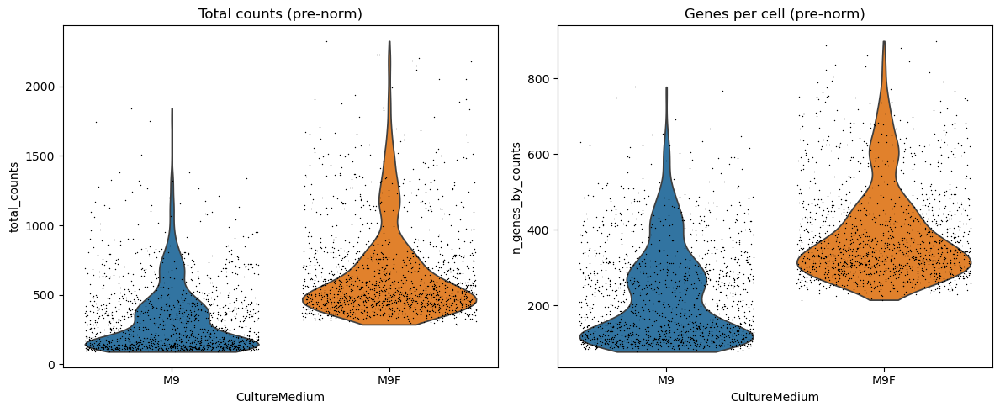

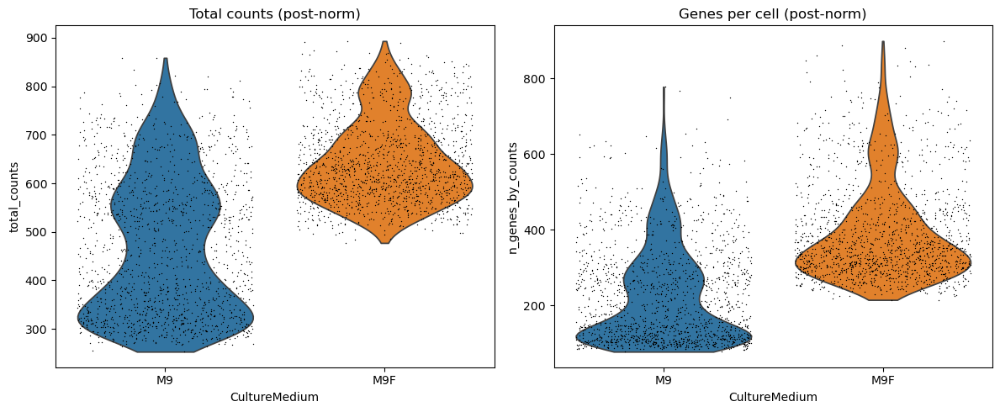

893.2125244140625
Nombre de gènes : 1676


In [87]:
# %%
# Filter genes based on gene_pass_union_OD_15pct
adata_union = test[:, test.var["gene_pass_union_OD_15pct"] == True].copy()
print(f"Nombre de gènes après filtrage: {adata_union.shape[1]}")

# Save raw data before normalization
adata_union.layers["raw"] = adata_union.X.copy()

print(adata_union.obs["total_counts"].max())


# remove columns log1p
adata_union.obs.drop(
    columns=["log1p_total_counts", "log1p_n_genes_by_counts"], inplace=True
)

# Calculate total counts before normalization
# inplace=True modifies the AnnData object directly instead of returning a new one
sc.pp.calculate_qc_metrics(adata_union, inplace=True)

# Visualize pre-normalization data
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
sc.pl.violin(
    adata_union, "total_counts", groupby="CultureMedium", jitter=0.4, ax=ax1, show=False
)
ax1.set_title("Total counts (pre-norm)")
sc.pl.violin(
    adata_union,
    "n_genes_by_counts",
    groupby="CultureMedium",
    jitter=0.4,
    ax=ax2,
    show=False,
)
ax2.set_title("Genes per cell (pre-norm)")
plt.tight_layout()
plt.show()

# Normalize data
# inplace=True modifies the AnnData object directly instead of creating a new one
sc.pp.normalize_total(adata_union, inplace=True, target_sum=2000)
# Logarithmize the data
sc.pp.log1p(adata_union)
# Recalculate total counts after normalization
# inplace=True modifies the metrics in place rather than returning them
sc.pp.calculate_qc_metrics(adata_union, inplace=True)


# Visualize post-normalization data
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
sc.pl.violin(
    adata_union, "total_counts", groupby="CultureMedium", jitter=0.4, ax=ax1, show=False
)
ax1.set_title("Total counts (post-norm)")
sc.pl.violin(
    adata_union,
    "n_genes_by_counts",
    groupby="CultureMedium",
    jitter=0.4,
    ax=ax2,
    show=False,
)
ax2.set_title("Genes per cell (post-norm)")
plt.tight_layout()
plt.show()

print(adata_union.obs["total_counts"].max())
print(f"Nombre de gènes : {adata_union.shape[1]}")

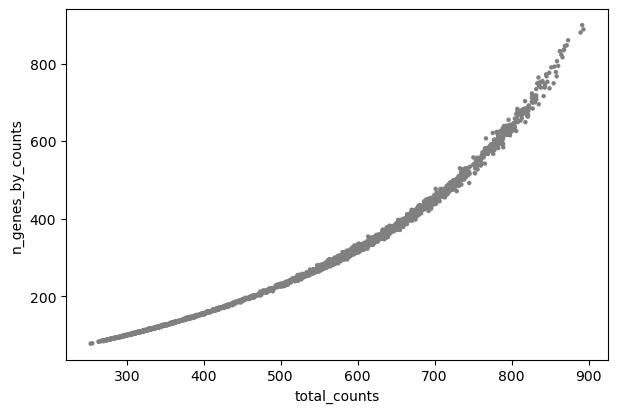

In [88]:
sc.pl.scatter(adata_union, "total_counts", "n_genes_by_counts")

In [89]:
# Step 3: Subset to HVGs
# We need to calculate highly variable genes before subsetting
sc.pp.highly_variable_genes(adata_union, n_top_genes=500, batch_key="RepBio")

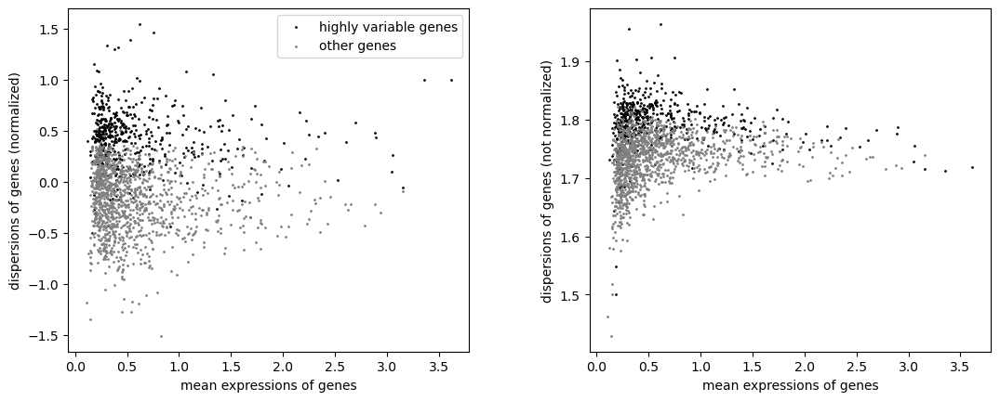

In [90]:
sc.pl.highly_variable_genes(adata_union)

In [91]:
adata_union = adata_union[:, adata_union.var.highly_variable]

In [92]:
# Step 4: Scale data
sc.pp.scale(adata_union)

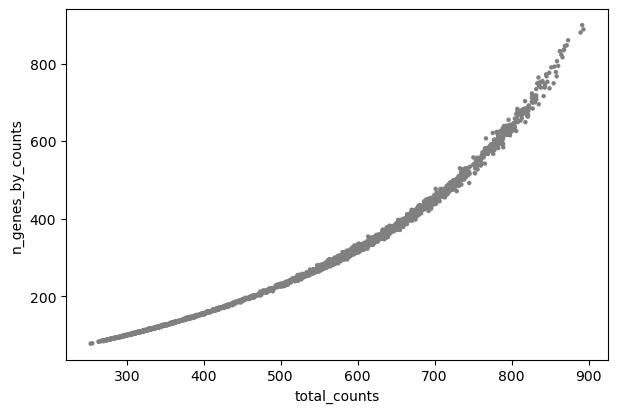

In [93]:
sc.pl.scatter(adata_union, "total_counts", "n_genes_by_counts")

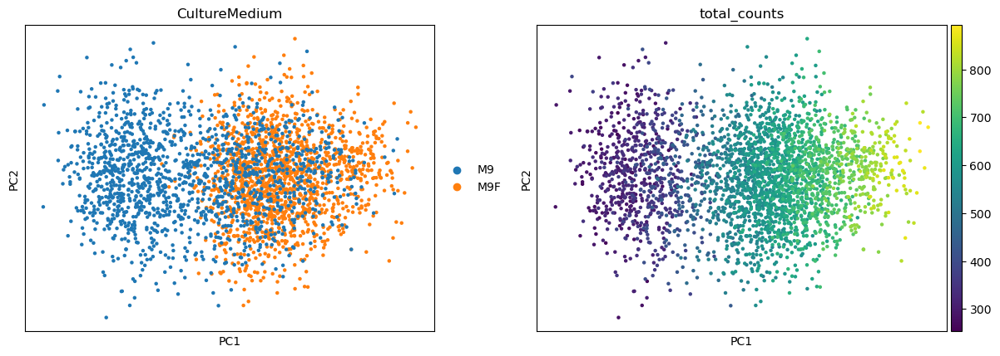

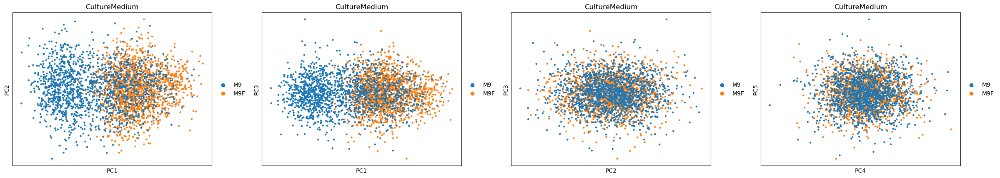

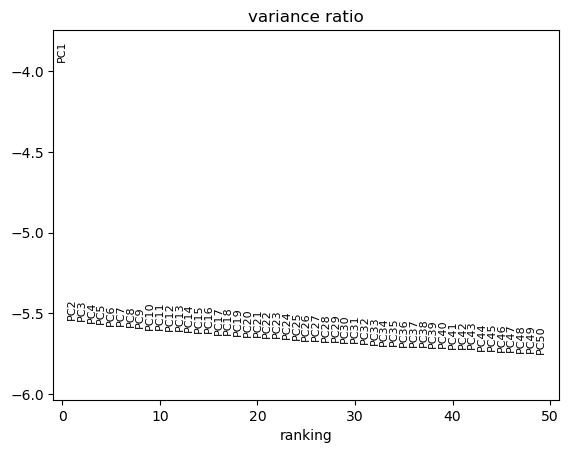

In [94]:
sc.tl.pca(adata_union)

# %%
sc.pl.pca(adata_union, color=["CultureMedium", "total_counts"])

# %%
sc.pl.pca(adata_union, color="CultureMedium", components=["1,2", "1,3", "2,3", "4,5"])

# %%
sc.pl.pca_variance_ratio(adata_union, n_pcs=50, log=True)

In [95]:
sc.pp.neighbors(adata_union)

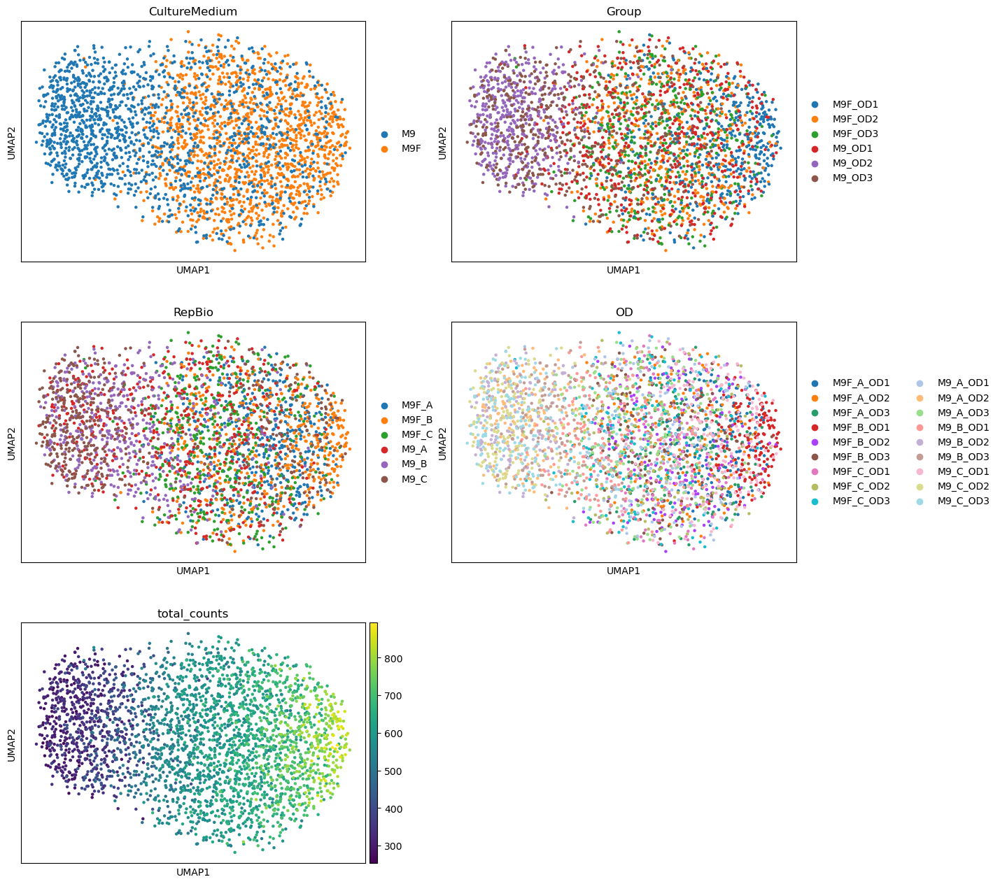

In [96]:
sc.tl.umap(adata_union)

# %%
sc.pl.umap(
    adata_union,
    color=["CultureMedium", "Group", "RepBio", "OD", "total_counts"],
    ncols=2,
)


# %%

In [97]:
# Using the igraph implementation and a fixed number of iterations can be significantly faster, especially for larger datasets
sc.tl.leiden(adata_union, flavor="igraph", n_iterations=2)

for res in [0.02, 0.5, 0.75, 1.0, 1.5, 2.0]:
    sc.tl.leiden(
        adata_union, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph"
    )
# print available keys
print(adata_union.obs.keys())

Index(['barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3',
       'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric',
       'OD_measured', 'Group', 'n_genes', 'RepTech_suffix', 'RepBio_suffix',
       'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes',
       'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',
       'pct_counts_in_top_500_genes', 'group', 'outlier',
       'log1p_n_genes_by_counts', 'log1p_total_counts', 'leiden',
       'leiden_res_0.02', 'leiden_res_0.50', 'leiden_res_0.75',
       'leiden_res_1.00', 'leiden_res_1.50', 'leiden_res_2.00'],
      dtype='object')


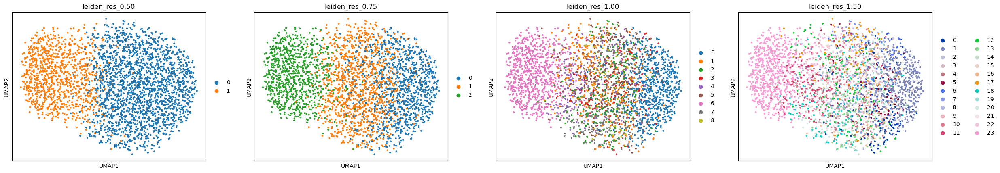

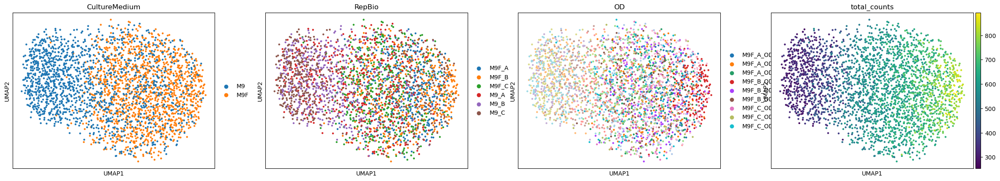

In [98]:
sc.pl.umap(
    adata_union,
    color=[
        "leiden_res_0.50",
        "leiden_res_0.75",
        "leiden_res_1.00",
        "leiden_res_1.50",
    ],
)

# %%
sc.pl.umap(adata_union, color=["CultureMedium", "RepBio", "OD", "total_counts"])

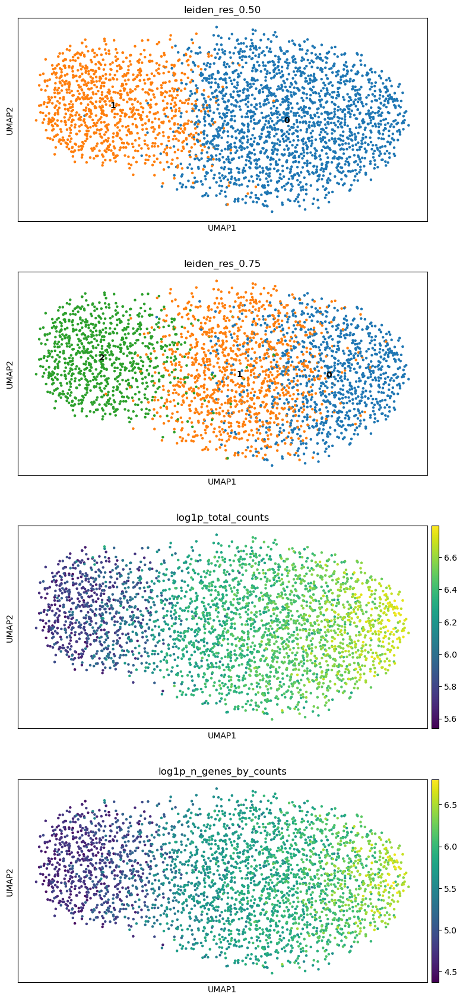

In [99]:
sc.pl.umap(
    adata_union,
    color=[
        "leiden_res_0.50",
        "leiden_res_0.75",
        "log1p_total_counts",
        "log1p_n_genes_by_counts",
    ],
    wspace=0.5,
    ncols=1,
    legend_loc="on data",
)




In [100]:
sc.pl.dotplot(
    adata_union,
    groupby="leiden_res_0.50",
    standard_scale="var",
    var_names=adata_union.var_names,
)

In [101]:
#
# Perform differential expression analysis between clusters using current X matrix
sc.tl.rank_genes_groups(
    adata_union, groupby="leiden_res_0.50", method="wilcoxon", use_raw=False
)

In [102]:
adata_union.var.head(20)

,feature_id,gene_id,feature_type,Accession,Begin,End,Chromosome,Orientation,Name,Symbol,...,original_gene_ids,var_counts,highly_variable,means,dispersions,dispersions_norm,highly_variable_nbatches,highly_variable_intersection,mean,std
final_gene_name,,,,,,,,,,,,,,,,,,,,,
QLH64-00070,gene-QLH64_00070,QLH64-00070,Gene Expression,CP125961.1,18380,19696,chromosome,minus,ATP-binding protein,NaN,...,QLH64-00070,0.057783,True,0.208840,1.775066,0.609094,3,False,0.080323,0.363891
QLH64-00235,gene-QLH64_00235,QLH64-00235,Gene Expression,CP125961.1,64303,65064,chromosome,plus,LuxR family transcriptional regulator,NaN,...,QLH64-00235,0.134454,True,0.389955,1.802068,0.660688,4,False,0.166457,0.510673
leuA_1,gene-QLH64_00385,QLH64-00385,Gene Expression,CP125961.1,106188,107882,unknown,plus,2-isopropylmalate synthase,leuA_1,...,QLH64-00385,1.080276,True,1.447608,1.770699,0.226428,3,False,0.930211,1.009656
QLH64-00395,gene-QLH64_00395,QLH64-00395,Gene Expression,CP125961.1,108834,110336,chromosome,plus,TolC family protein,NaN,...,QLH64-00395,0.327353,True,0.737806,1.796699,0.328187,3,False,0.363299,0.719961
QLH64-00410,gene-QLH64_00410,QLH64-00410,Gene Expression,CP125961.1,113504,114280,chromosome,plus,DUF3050 domain-containing protein,NaN,...,QLH64-00410,2.943357,True,2.049014,1.748617,-0.038401,3,False,1.570024,1.101773
QLH64-00420,gene-QLH64_00420,QLH64-00420,Gene Expression,CP125961.1,114650,115579,chromosome,plus,diiron oxygenase,NaN,...,QLH64-00420,1.913858,True,1.789466,1.800624,0.561517,3,False,1.276588,1.079497
QLH64-00520,gene-QLH64_00520,QLH64-00520,Gene Expression,CP125961.1,137114,139981,chromosome,minus,FAD-binding and (Fe-S)-binding domain-containi...,NaN,...,QLH64-00520,0.157233,True,0.460702,1.818325,0.571473,3,False,0.200873,0.555280
recN,gene-QLH64_00580,QLH64-00580,Gene Expression,CP125961.1,150457,152130,unknown,minus,DNA repair protein RecN,recN,...,QLH64-00580,0.059073,True,0.224020,1.822611,0.444310,3,False,0.086591,0.375969
grpE,gene-QLH64_00585,QLH64-00585,Gene Expression,CP125961.1,152372,152938,unknown,plus,nucleotide exchange factor GrpE,grpE,...,QLH64-00585,0.224482,True,0.615369,1.825945,0.612265,3,False,0.280166,0.654046


In [103]:
# Étape 1 : Obtenir les 20 gènes les plus différentiellement exprimés du groupe "1"
top_genes_group1 = sc.get.rank_genes_groups_df(adata_union, group="1").head(20)
gene_list_group1 = top_genes_group1["names"].tolist()

print("Top 20 differentially expressed genes in group 1:")
print(f"Gene names: {gene_list_group1}")

# Étape 2 : Vérifier les colonnes de adata_union.var
print(f"Available columns in adata_union.var: {list(adata_union.var.columns)}")

# Étape 3 : Associer les gènes DE à leurs informations via la colonne 'final_gene_name'
if "final_gene_name" in adata_union.var.columns:
    mask = adata_union.var["final_gene_name"].isin(gene_list_group1)
    gene_info = adata_union.var[mask]

    if not gene_info.empty:
        print("Gene characteristics (matched via final_gene_name):")
        display_cols = [
            "final_gene_name",
            "n_cells_by_counts",
            "mean_counts",
            "total_counts",
        ]
        available_cols = [col for col in display_cols if col in gene_info.columns]
        print(gene_info[available_cols])
    else:
        print("No genes matched in 'final_gene_name'.")
else:
    print("Column 'final_gene_name' not found in adata_union.var.")

# Étape 4 : Afficher les statistiques de DE
print("\nDifferential expression statistics:")
print(top_genes_group1[["names", "scores", "logfoldchanges", "pvals", "pvals_adj"]])

Top 20 differentially expressed genes in group 1:
Gene names: ['QLH64-05400', 'QLH64-01790', 'QLH64-29905', 'QLH64-12200', 'treA', 'QLH64-24105', 'QLH64-08840', 'QLH64-29680', 'dapC', 'QLH64-01810', 'codA', 'QLH64-28560', 'QLH64-24040', 'QLH64-04945', 'QLH64-05120', 'hemE', 'QLH64-27625', 'QLH64-26080', 'QLH64-27790', 'QLH64-04580']
Available columns in adata_union.var: ['feature_id', 'gene_id', 'feature_type', 'Accession', 'Begin', 'End', 'Chromosome', 'Orientation', 'Name', 'Symbol', 'Gene ID', 'Gene Type', 'Transcripts accession', 'Transcript name', 'Protein accession', 'Protein name', 'Protein length', 'symbol_old', 'locus_tag_old', 'symbol_renamed', 'final_gene_name', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'gene_pass_union_OD_5pct', 'gene_pass_intersection_OD_5pct', 'gene_pass_union_OD_10pct', 'gene_pass_intersection_OD_10pct', 'gene_pass_union_OD_15pct', 'gene_pass_intersection_OD_15pct', 


Si tu fais un split des counts pour séparer le signal biologique du bruit technique, il faut connaître la nature de la distribution :
	•	Si les données sont Poisson → le splitting est plus simple (le bruit est symétrique).
	•	Si elles sont NB / surdispersionnées → il faut un modèle plus complexe (bruit variable selon les gènes).

In [104]:
sc.get.rank_genes_groups_df(adata_union, group="0").head(20)

,names,scores,logfoldchanges,pvals,pvals_adj
0,rplJ,12.022217,NaN,2.715851e-33,1.357925e-30
1,ppsA,11.951109,NaN,6.406439e-33,1.601610e-30
2,QLH64-00945,11.473992,NaN,1.782415e-30,2.970692e-28
3,QLH64-07155,11.367157,NaN,6.094050e-30,7.617562e-28
4,hcnC,11.270605,NaN,1.833058e-29,1.833058e-27
5,glgA,11.101437,NaN,1.234434e-28,1.028695e-26
6,rpsG,10.782740,NaN,4.153276e-27,2.966625e-25
7,rne,10.713791,NaN,8.769556e-27,5.480972e-25
8,clpB,10.696287,NaN,1.059388e-26,5.885491e-25
9,QLH64-04055,10.685956,NaN,1.184225e-26,5.921127e-25


categories: 0, 1, 2
var_group_labels: 0, 1


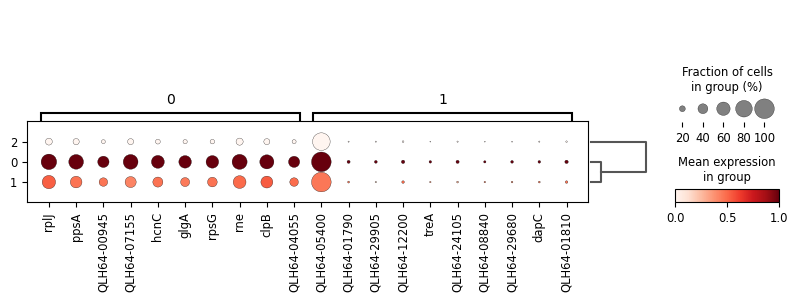

In [105]:
sc.pl.rank_genes_groups_dotplot(
    adata_union, groupby="leiden_res_0.75", standard_scale="var", n_genes=10
)

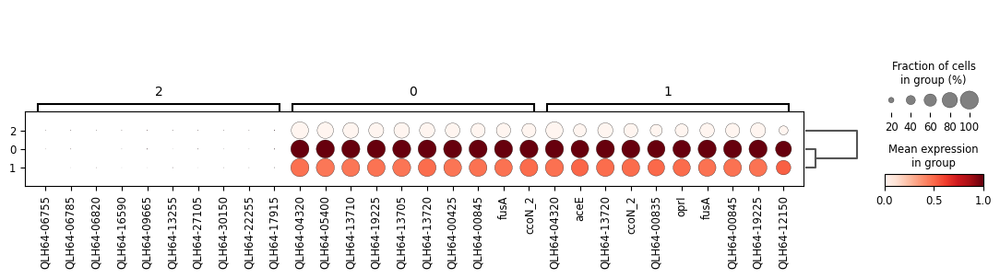

KeyError: "None of [Index(['3'], dtype='object')] are in the [columns]"

In [106]:
# Perform differential expression analysis between clusters
sc.tl.rank_genes_groups(adata_union, groupby="leiden_res_0.75", method="wilcoxon")

# Get the top 5 differentially expressed genes for cluster 1
sc.get.rank_genes_groups_df(adata_union, group="1").head(5)
sc.pl.rank_genes_groups_dotplot(
    adata_union, groupby="leiden_res_0.75", standard_scale="var", n_genes=10
)
sc.get.rank_genes_groups_df(adata_union, group="2").head(5)

dc_cluster_genes = sc.get.rank_genes_groups_df(adata_union, group="3").head(5)["names"]
sc.pl.umap(
    adata_union,
    color=[*dc_cluster_genes, "leiden_res_0.75"],
    # legend_loc="on data",
    frameon=False,
    ncols=3,
)


Si tu fais un split des counts pour séparer le signal biologique du bruit technique, il faut connaître la nature de la distribution :
	•	Si les données sont Poisson → le splitting est plus simple (le bruit est symétrique).
	•	Si elles sont NB / surdispersionnées → il faut un modèle plus complexe (bruit variable selon les gènes).


Si tu fais un split des counts pour séparer le signal biologique du bruit technique, il faut connaître la nature de la distribution :
	•	Si les données sont Poisson → le splitting est plus simple (le bruit est symétrique).
	•	Si elles sont NB / surdispersionnées → il faut un modèle plus complexe (bruit variable selon les gènes).


Si tu fais un split des counts pour séparer le signal biologique du bruit technique, il faut connaître la nature de la distribution :
	•	Si les données sont Poisson → le splitting est plus simple (le bruit est symétrique).
	•	Si elles sont NB / surdispersionnées → il faut un modèle plus complexe (bruit variable selon les gènes).


Si tu fais un split des counts pour séparer le signal biologique du bruit technique, il faut connaître la nature de la distribution :
	•	Si les données sont Poisson → le splitting est plus simple (le bruit est symétrique).
	•	Si elles sont NB / surdispersionnées → il faut un modèle plus complexe (bruit variable selon les gènes).

va maintenant essayer de faire analyse sur un sous cluster : M9F car plus de signal 
OD2 -> car peut de variance entre rep tech

In [45]:
# filter M9F_OD2

adata_M9F_OD2 = data_all.copy()
adata_M9F_OD2 = adata_M9F_OD2[adata_M9F_OD2.obs["Group"] == "M9F_OD2"]

adata_M9F_OD2.obs["Group"].value_counts()
adata_M9F_OD2.obs.head()

,barcode,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,CultureMedium,RepBio,OD,RepTech,ODt,OD_theoric,...,RepBio_suffix,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,outlier
barcode,,,,,,,,,,,,,,,,,,,,,
CGCATACA_CCATCCTC_CCGAGAAA,CGCATACA_CCATCCTC_CCGAGAAA,E4,H1,D6,M9F,M9F_A,M9F_A_OD2,M9F_A_OD2_1,OD2,0.5,...,A,360,5.888878,483,6.182085,32.712215,46.169772,66.873706,100.0,False
ACCTCCAA_CCATCCTC_CCGAGAAA,ACCTCCAA_CCATCCTC_CCGAGAAA,E4,H1,B8,M9F,M9F_A,M9F_A_OD2,M9F_A_OD2_1,OD2,0.5,...,A,374,5.926926,501,6.218600,30.139721,45.309381,65.269461,100.0,False
CAACCACA_GTCTGTCA_CCGAGAAA,CAACCACA_GTCTGTCA_CCGAGAAA,E4,E10,C6,M9F,M9F_A,M9F_A_OD2,M9F_A_OD2_1,OD2,0.5,...,A,288,5.666427,378,5.937536,34.920635,50.264550,76.719577,100.0,False
CTGGCATA_CTAAGGTC_CCGAGAAA,CTGGCATA_CTAAGGTC_CCGAGAAA,E4,H7,D9,M9F,M9F_A,M9F_A_OD2,M9F_A_OD2_1,OD2,0.5,...,A,291,5.676754,383,5.950643,34.464752,50.130548,76.240209,100.0,False
AACAACCA_CCGTGAGA_CCGAGAAA,AACAACCA_CCGTGAGA_CCGAGAAA,E4,D2,B1,M9F,M9F_A,M9F_A_OD2,M9F_A_OD2_1,OD2,0.5,...,A,286,5.659482,378,5.937536,35.449735,50.793651,77.248677,100.0,False


In [ ]:
# recalculate stats :
sc.pp.calculate_qc_metrics(adata_M9F_OD2, inplace=True, log1p=True)
adata_M9F_OD2.obs.head()

,barcode,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,CultureMedium,RepBio,OD,RepTech,ODt,OD_theoric,...,RepBio_suffix,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,outlier
barcode,,,,,,,,,,,,,,,,,,,,,
CGCATACA_CCATCCTC_CCGAGAAA,CGCATACA_CCATCCTC_CCGAGAAA,E4,H1,D6,M9F,M9F_A,M9F_A_OD2,M9F_A_OD2_1,OD2,0.5,...,A,360,5.888878,483,6.182085,32.712215,46.169772,66.873706,100.0,False
ACCTCCAA_CCATCCTC_CCGAGAAA,ACCTCCAA_CCATCCTC_CCGAGAAA,E4,H1,B8,M9F,M9F_A,M9F_A_OD2,M9F_A_OD2_1,OD2,0.5,...,A,374,5.926926,501,6.218600,30.139721,45.309381,65.269461,100.0,False
CAACCACA_GTCTGTCA_CCGAGAAA,CAACCACA_GTCTGTCA_CCGAGAAA,E4,E10,C6,M9F,M9F_A,M9F_A_OD2,M9F_A_OD2_1,OD2,0.5,...,A,288,5.666427,378,5.937536,34.920635,50.264550,76.719577,100.0,False
CTGGCATA_CTAAGGTC_CCGAGAAA,CTGGCATA_CTAAGGTC_CCGAGAAA,E4,H7,D9,M9F,M9F_A,M9F_A_OD2,M9F_A_OD2_1,OD2,0.5,...,A,291,5.676754,383,5.950643,34.464752,50.130548,76.240209,100.0,False
AACAACCA_CCGTGAGA_CCGAGAAA,AACAACCA_CCGTGAGA_CCGAGAAA,E4,D2,B1,M9F,M9F_A,M9F_A_OD2,M9F_A_OD2_1,OD2,0.5,...,A,286,5.659482,378,5.937536,35.449735,50.793651,77.248677,100.0,False


In [51]:
adata_M9F_OD2.var.head()

Index(['feature_id', 'gene_id', 'feature_type', 'Accession', 'Begin', 'End',
       'Chromosome', 'Orientation', 'Name', 'Symbol', 'Gene ID', 'Gene Type',
       'Transcripts accession', 'Transcript name', 'Protein accession',
       'Protein name', 'Protein length', 'symbol_old', 'locus_tag_old',
       'symbol_renamed', 'final_gene_name', 'n_cells_by_counts', 'mean_counts',
       'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts',
       'log1p_total_counts', 'n_cells', 'gene_pass_union_OD_5pct',
       'gene_pass_intersection_OD_5pct', 'gene_pass_union_OD_10pct',
       'gene_pass_intersection_OD_10pct', 'gene_pass_union_OD_15pct',
       'gene_pass_intersection_OD_15pct', 'original_gene_ids', 'var_counts'],
      dtype='object')

In [52]:
adata_M9F_OD2.var.columns

Index(['feature_id', 'gene_id', 'feature_type', 'Accession', 'Begin', 'End',
       'Chromosome', 'Orientation', 'Name', 'Symbol', 'Gene ID', 'Gene Type',
       'Transcripts accession', 'Transcript name', 'Protein accession',
       'Protein name', 'Protein length', 'symbol_old', 'locus_tag_old',
       'symbol_renamed', 'final_gene_name', 'n_cells_by_counts', 'mean_counts',
       'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts',
       'log1p_total_counts', 'n_cells', 'gene_pass_union_OD_5pct',
       'gene_pass_intersection_OD_5pct', 'gene_pass_union_OD_10pct',
       'gene_pass_intersection_OD_10pct', 'gene_pass_union_OD_15pct',
       'gene_pass_intersection_OD_15pct', 'original_gene_ids', 'var_counts'],
      dtype='object')

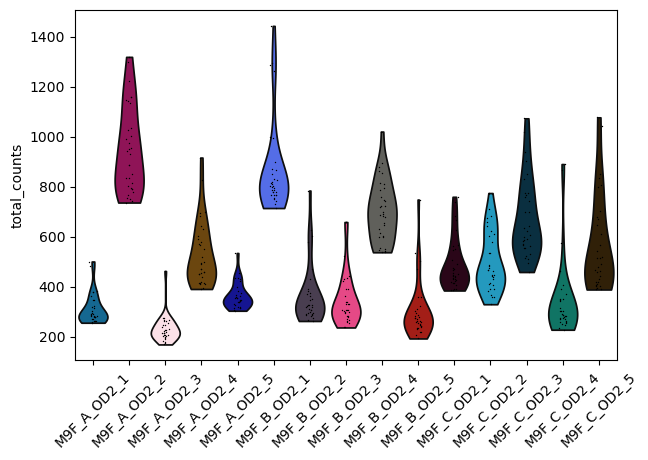

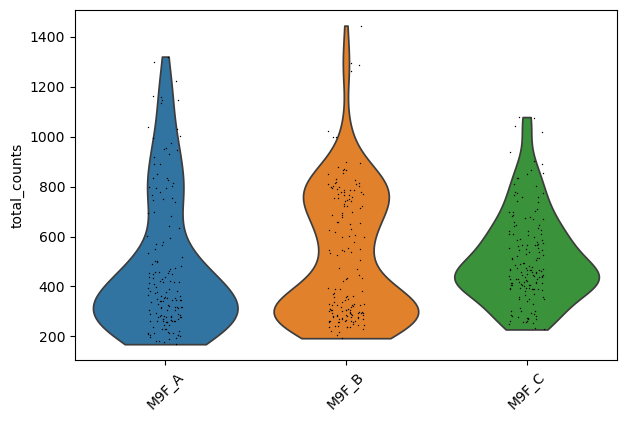

In [57]:
sc.pl.violin(adata_M9F_OD2, "total_counts", groupby="RepTech", rotation=45)
sc.pl.violin(adata_M9F_OD2, "total_counts", groupby="RepBio", rotation=45)

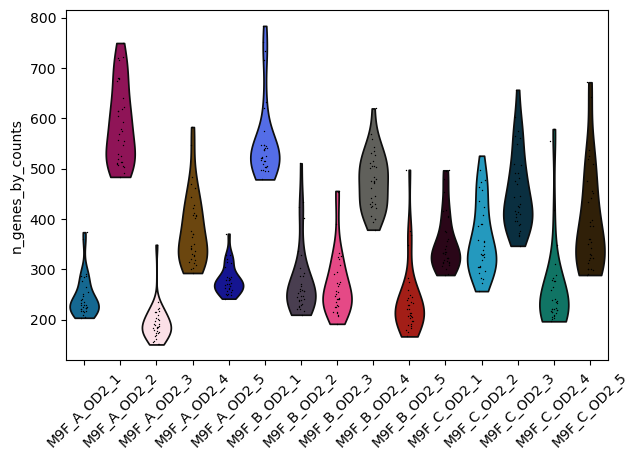

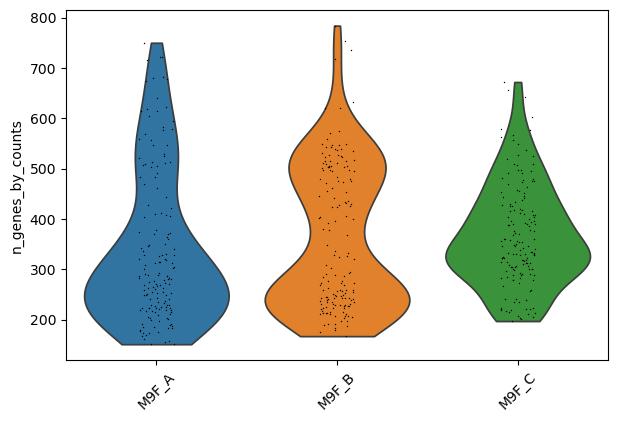

In [58]:
sc.pl.violin(adata_M9F_OD2, "n_genes_by_counts", groupby="RepTech", rotation=45)
sc.pl.violin(adata_M9F_OD2, "n_genes_by_counts", groupby="RepBio", rotation=45)

In [66]:
print(f"Number of cells: {adata_M9F_OD2.n_obs}")
print(f"Cells names: {adata_M9F_OD2.obs_names}")
print(f"Number of genes: {adata_M9F_OD2.n_vars}")
print(f"Genes names: {adata_M9F_OD2.var_names}")


# %%

# %%

# %%

# %%

Number of cells: 489
Cells names: Index(['CGCATACA_CCATCCTC_CCGAGAAA', 'ACCTCCAA_CCATCCTC_CCGAGAAA',
       'CAACCACA_GTCTGTCA_CCGAGAAA', 'CTGGCATA_CTAAGGTC_CCGAGAAA',
       'AACAACCA_CCGTGAGA_CCGAGAAA', 'AATCCGTC_GACAGTGC_CCGAGAAA',
       'CCTAATCC_GACAGTGC_CCGAGAAA', 'GCTCGGTA_CCTCCTGA_CCGAGAAA',
       'TGGTGGTA_AACCGAGA_CCGAGAAA', 'CGCTGATC_TGGAACAA_CCGAGAAA',
       ...
       'TCTTCACA_GAATCTGA_GCAAATTC', 'GTACGCAA_ATCCTGTA_GCAAATTC',
       'ATTGGCTC_AATCCGTC_GCAAATTC', 'ACCTCCAA_AAGGTACA_GCAAATTC',
       'AGCAGGAA_CTCAATGA_GCAAATTC', 'AGTACAAG_ATCATTCC_GCAAATTC',
       'AATCCGTC_ACGTATCA_GCAAATTC', 'ACCTCCAA_CCTAATCC_GCAAATTC',
       'CATCAAGT_AACAACCA_GCAAATTC', 'GCGAGTAA_CAGATCTG_GCAAATTC'],
      dtype='object', name='barcode', length=489)
Number of genes: 5624
Genes names: Index(['recC', 'recB', 'recD', 'QLH64-00045', 'QLH64-00050', 'QLH64-00055',
       'QLH64-00060', 'QLH64-00070', 'QLH64-00075', 'QLH64-00080',
       ...
       'QLH64-31200', 'QLH64-31205', 'QLH64-3

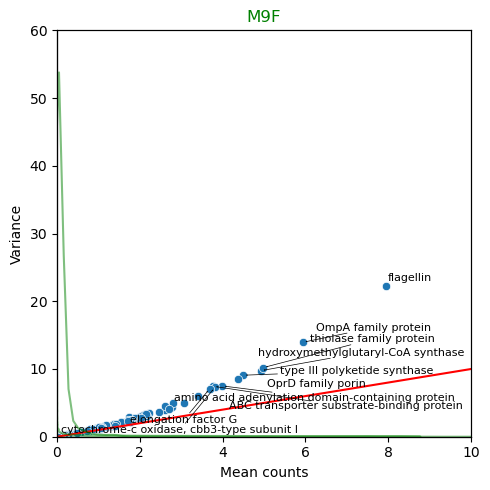

In [ ]:
# Import required library
from scipy import stats

data_f = adata_M9F_OD2.copy()
# Calculate variance and mean counts
data_f.var["var_counts"] = np.asarray(np.var(data_f.X.toarray(), axis=0)).squeeze()
data_f.var["mean_counts"] = np.asarray(np.mean(data_f.X.toarray(), axis=0)).squeeze()

# Create figure with subplots - one per culture medium
n_media = len(data_f.obs["CultureMedium"].unique())
if n_media == 1:
    fig, axes = plt.subplots(1, 1, figsize=(5, 5))
    axes = [axes]  # Convert single Axes to list for consistent indexing
else:
    fig, axes = plt.subplots(1, n_media, figsize=(10 * n_media / 2, 5))

# Set fixed axis limits
fixed_max_mean = 10  # Fixed x-axis limit
fixed_max_var = 60  # Fixed y-axis limit

# Find global max density for consistent scaling
max_density_var = 0
max_density_mean = 0

# Sort media to have M9F first, then M9
media_order = sorted(
    data_f.obs["CultureMedium"].unique(),
    key=lambda x: "0" if x.startswith("M9F") else "1",
)

for medium in media_order:
    medium_cells = data_f.obs["CultureMedium"] == medium
    medium_data = data_f[medium_cells]

    medium_var = np.asarray(np.var(medium_data.X.toarray(), axis=0)).squeeze()
    medium_mean = np.asarray(np.mean(medium_data.X.toarray(), axis=0)).squeeze()

    # Calculate KDE for variance and mean
    kde_var = stats.gaussian_kde(medium_var)
    kde_mean = stats.gaussian_kde(medium_mean)

    # Get max density values
    max_density_var = max(max_density_var, kde_var(medium_var).max())
    max_density_mean = max(max_density_mean, kde_mean(medium_mean).max())

for idx, medium in enumerate(media_order):
    # Filter data for current medium
    medium_cells = data_f.obs["CultureMedium"] == medium
    medium_data = data_f[medium_cells]

    # Calculate medium-specific variance and mean counts
    medium_var = np.asarray(np.var(medium_data.X.toarray(), axis=0)).squeeze()
    medium_mean = np.asarray(np.mean(medium_data.X.toarray(), axis=0)).squeeze()

    # Create temporary dataframe for plotting
    plot_df = pd.DataFrame(
        {
            "mean_counts": medium_mean,
            "var_counts": medium_var,
            "Name": data_f.var["Name"],
        },
        index=data_f.var.index,
    )

    # Create scatter plot
    sns.scatterplot(data=plot_df, x="mean_counts", y="var_counts", ax=axes[idx])

    # Add density plots on margins with consistent scaling
    # Top margin density plot
    ax_top = axes[idx].twinx()
    sns.kdeplot(data=plot_df["var_counts"], ax=ax_top, color="green", alpha=0.5)
    ax_top.set_ylim(0, max_density_var * 1.1)  # Add 10% padding
    ax_top.spines["right"].set_visible(False)
    ax_top.set_ylabel("")
    ax_top.set_yticks([])

    # Right margin density plot
    ax_right = axes[idx].twiny()
    sns.kdeplot(
        data=plot_df["mean_counts"],
        ax=ax_right,
        color="green",
        alpha=0.5,
        vertical=True,
    )
    ax_right.set_xlim(0, max_density_mean * 1.1)  # Add 10% padding
    ax_right.spines["top"].set_visible(False)
    ax_right.set_xlabel("")
    ax_right.set_xticks([])

    # Add diagonal line
    axes[idx].plot(
        [0, fixed_max_mean],
        [0, fixed_max_mean],
        color="red",
    )

    # Set fixed axis limits
    axes[idx].set_xlim(0, fixed_max_mean)
    axes[idx].set_ylim(0, fixed_max_var)

    # Get top 10 genes by mean counts for this medium
    top_10_genes = plot_df.nlargest(10, "mean_counts")

    # Create labels for gene Names
    labels = []
    for _, (gene_name, row) in enumerate(top_10_genes.iterrows(), 1):
        gene_label = row["Name"] if not pd.isna(row["Name"]) else gene_name
        labels.append(
            {"x": row["mean_counts"], "y": row["var_counts"], "text": gene_label}
        )

    # Use adjustText to prevent label overlap
    texts = [
        axes[idx].text(label["x"], label["y"], label["text"], fontsize=8)
        for label in labels
    ]
    adjust_text(texts, arrowprops=dict(arrowstyle="->", color="black", lw=0.5))

    # Set title and labels with appropriate colors
    if medium.startswith("M9F"):
        axes[idx].set_title(f"{medium}", color="green")
    else:
        axes[idx].set_title(f"{medium}", color="red")
    axes[idx].set_xlabel("Mean counts")
    axes[idx].set_ylabel("Variance")

plt.tight_layout()
plt.show()

Nombre de gènes avant filtrage:  5624
Nombre de gènes après filtrage: 2968
1444


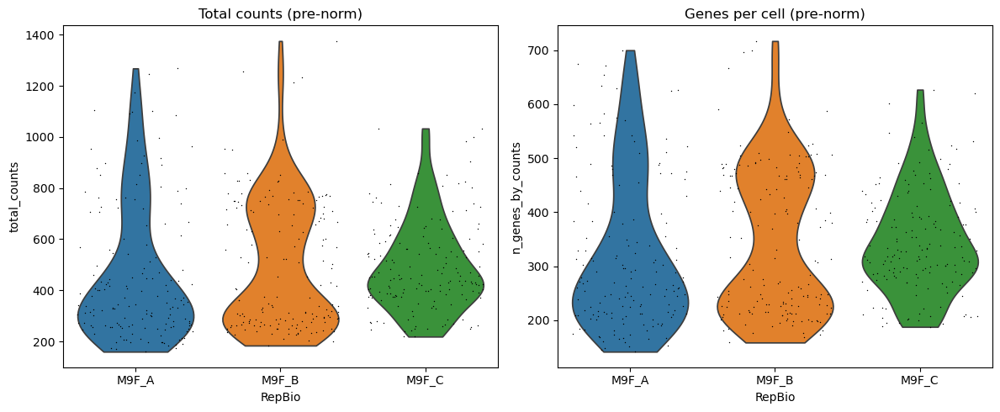

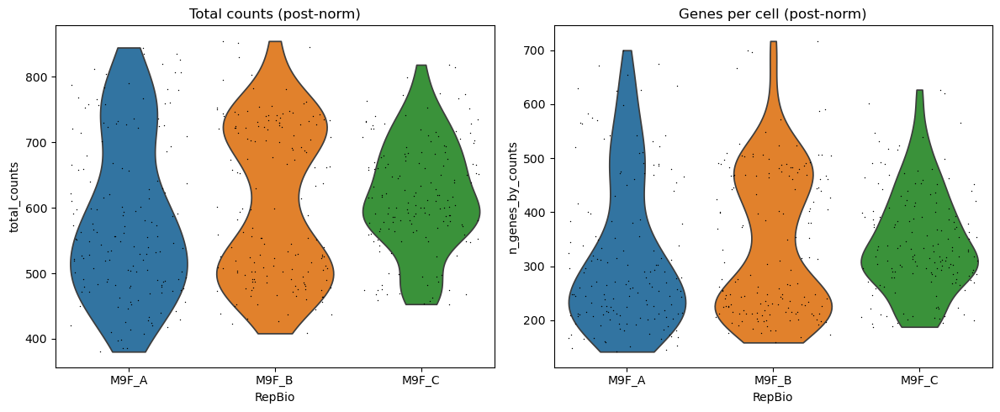

854.671875
Nombre de gènes : 2968


In [69]:
# %%
# Filter genes based on min 3 cells per gene
adata_f = adata_M9F_OD2.copy()
print("Nombre de gènes avant filtrage: ", adata_f.shape[1])
sc.pp.filter_genes(adata_f, min_cells=10, inplace=True)
print(f"Nombre de gènes après filtrage: {adata_f.shape[1]}")

# Save raw data before normalization
adata_f.layers["raw"] = adata_f.X.copy()

print(adata_f.obs["total_counts"].max())


# remove columns log1p
adata_f.obs.drop(
    columns=["log1p_total_counts", "log1p_n_genes_by_counts"], inplace=True
)

# Calculate total counts before normalization
# inplace=True modifies the AnnData object directly instead of returning a new one
sc.pp.calculate_qc_metrics(adata_f, inplace=True)

# Visualize pre-normalization data
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
sc.pl.violin(adata_f, "total_counts", groupby="RepBio", jitter=0.4, ax=ax1, show=False)
ax1.set_title("Total counts (pre-norm)")
sc.pl.violin(
    adata_f,
    "n_genes_by_counts",
    groupby="RepBio",
    jitter=0.4,
    ax=ax2,
    show=False,
)
ax2.set_title("Genes per cell (pre-norm)")
plt.tight_layout()
plt.show()

# Normalize data
# inplace=True modifies the AnnData object directly instead of creating a new one
sc.pp.normalize_total(adata_f, inplace=True, target_sum=2000)
# Logarithmize the data
sc.pp.log1p(adata_f)
# Recalculate total counts after normalization
# inplace=True modifies the metrics in place rather than returning them
sc.pp.calculate_qc_metrics(adata_f, inplace=True)


# Visualize post-normalization data
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
sc.pl.violin(adata_f, "total_counts", groupby="RepBio", jitter=0.4, ax=ax1, show=False)
ax1.set_title("Total counts (post-norm)")
sc.pl.violin(
    adata_f,
    "n_genes_by_counts",
    groupby="RepBio",
    jitter=0.4,
    ax=ax2,
    show=False,
)
ax2.set_title("Genes per cell (post-norm)")
plt.tight_layout()
plt.show()

print(adata_f.obs["total_counts"].max())
print(f"Nombre de gènes : {adata_f.shape[1]}")

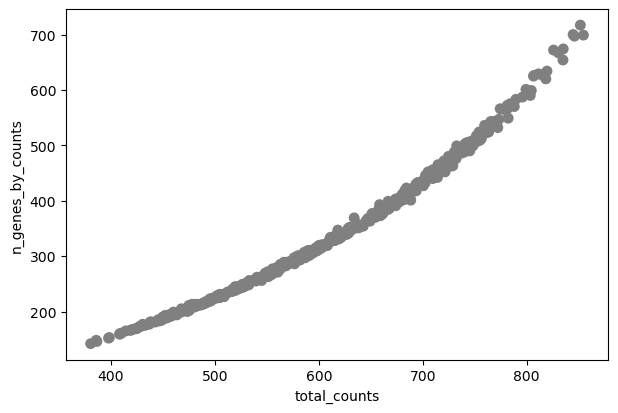

In [70]:
sc.pl.scatter(adata_f, "total_counts", "n_genes_by_counts")

In [71]:
# Step 3: Subset to HVGs
# We need to calculate highly variable genes before subsetting
sc.pp.highly_variable_genes(adata_f, n_top_genes=500, batch_key="RepTech")

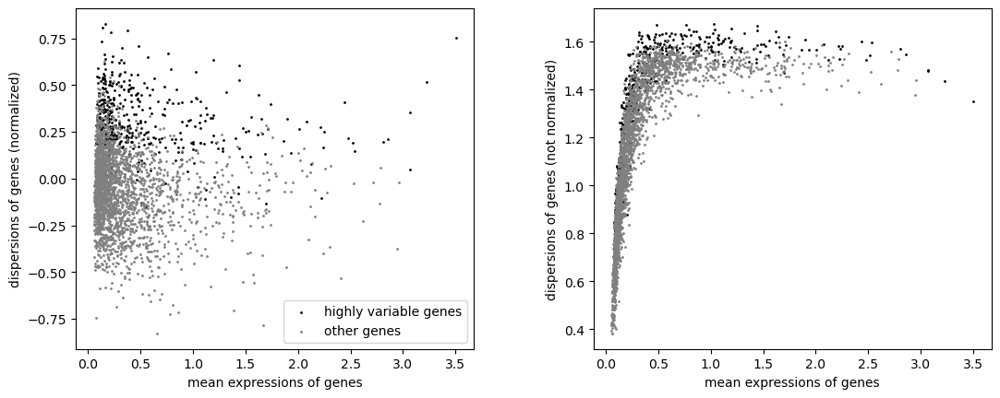

In [72]:
sc.pl.highly_variable_genes(adata_f)

In [73]:
adata_f = adata_f[:, adata_f.var.highly_variable]

In [75]:
# Step 4: Scale data
sc.pp.scale(adata_f)

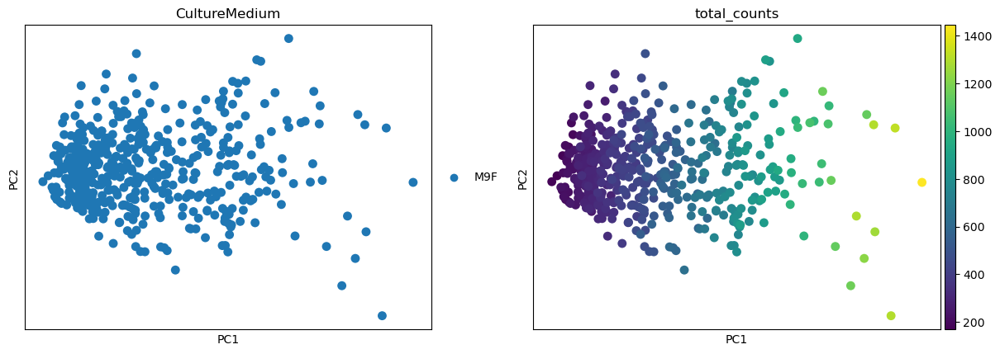

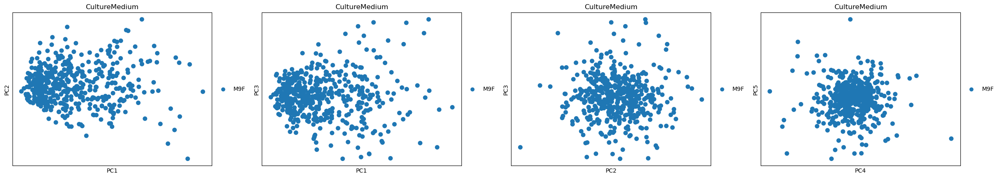

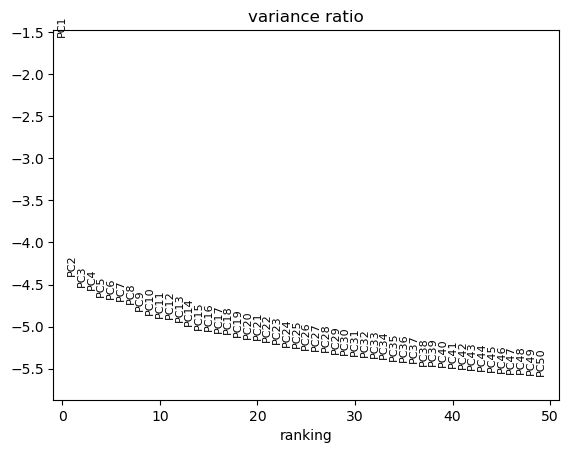

In [76]:
sc.tl.pca(data_f)

# %%
sc.pl.pca(data_f, color=["CultureMedium", "total_counts"])

# %%
sc.pl.pca(data_f, color="CultureMedium", components=["1,2", "1,3", "2,3", "4,5"])

# %%
sc.pl.pca_variance_ratio(data_f, n_pcs=50, log=True)

In [101]:
# Les paramètres modifiables pour sc.pp.neighbors sont:
# - n_neighbors: nombre de voisins (défaut=15)
# - n_pcs: nombre de composantes PCA à utiliser (défaut=None, utilise toutes)
# - knn: méthode de calcul des plus proches voisins ('umap', 'gauss', 'rapids') (défaut='umap')
# - random_state: graine aléatoire pour reproductibilité
# - method: méthode de calcul de la distance ('umap', 'gauss', 'rapids') (défaut='umap')
# - metric: métrique de distance ('euclidean', 'manhattan', 'chebyshev', etc) (défaut='euclidean')
# - use_rep: représentation à utiliser ('X_pca', 'X', etc) (défaut=None)

sc.pp.neighbors(
    adata_f,
    n_neighbors=10,  # Nombre de voisins à considérer
    use_rep="X_pca",  # Utilise la représentation PCA
    n_pcs=None,  # Utilise toutes les PCs
    random_state=0,  # Pour reproductibilité
    method="umap",  # Méthode de calcul
    metric="euclidean",  # Métrique de distance
)

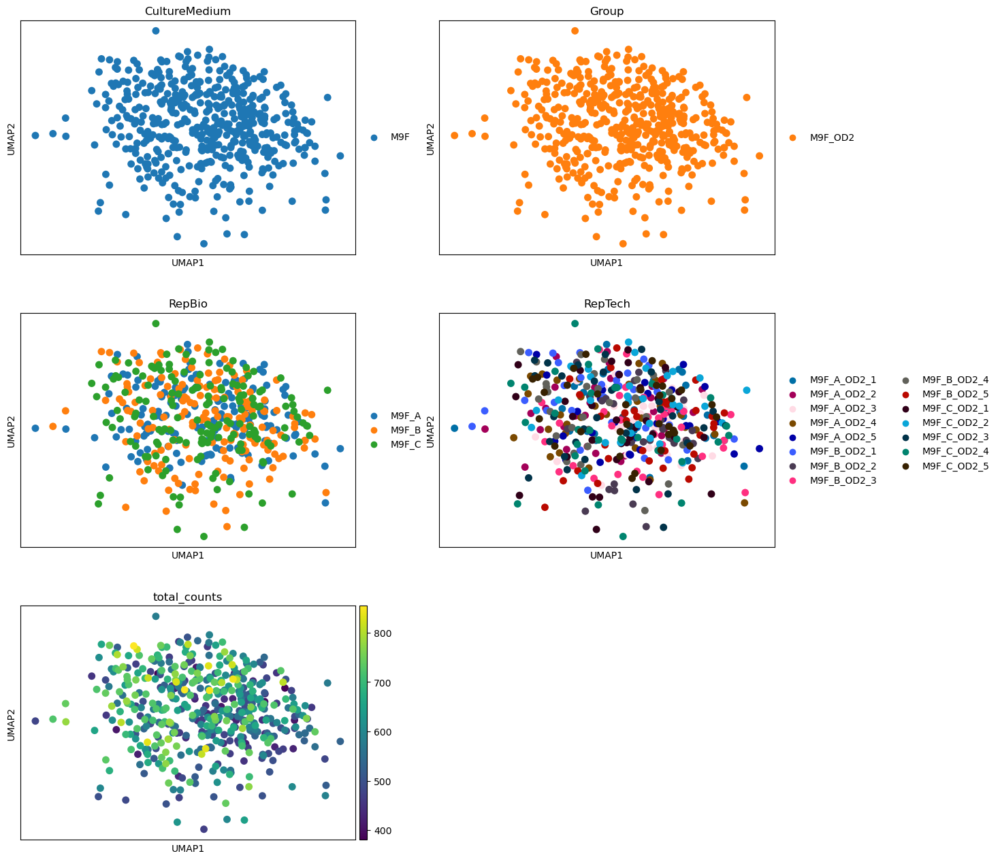

In [100]:
sc.tl.umap(adata_f, n_components=50)

# %%
sc.pl.umap(
    adata_f,
    color=["CultureMedium", "Group", "RepBio", "RepTech", "total_counts"],
    ncols=2,
)

In [91]:
# Using the igraph implementation and a fixed number of iterations can be significantly faster, especially for larger datasets
sc.tl.leiden(adata_f, flavor="igraph", n_iterations=50)

for res in [0.02, 0.5, 0.75, 1.0, 1.5, 2.0]:
    sc.tl.leiden(
        adata_f, key_added=f"leiden_res_{res:4.2f}", resolution=res, flavor="igraph"
    )
# print available keys
print(adata_f.obs.keys())

Index(['barcode', 'Well_loc_rd1', 'Well_loc_rd2', 'Well_loc_rd3',
       'CultureMedium', 'RepBio', 'OD', 'RepTech', 'ODt', 'OD_theoric',
       'OD_measured', 'Group', 'n_genes', 'RepTech_suffix', 'RepBio_suffix',
       'n_genes_by_counts', 'total_counts', 'pct_counts_in_top_50_genes',
       'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',
       'pct_counts_in_top_500_genes', 'outlier', 'log1p_n_genes_by_counts',
       'log1p_total_counts', 'leiden', 'leiden_res_0.02', 'leiden_res_0.50',
       'leiden_res_0.75', 'leiden_res_1.00', 'leiden_res_1.50',
       'leiden_res_2.00'],
      dtype='object')


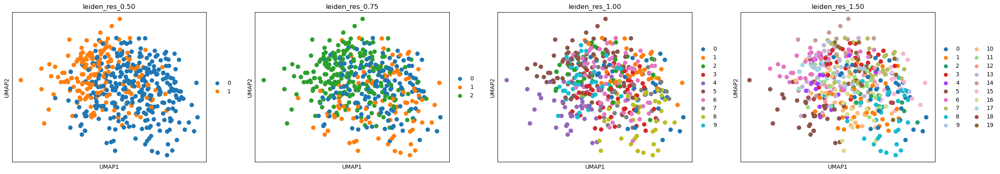

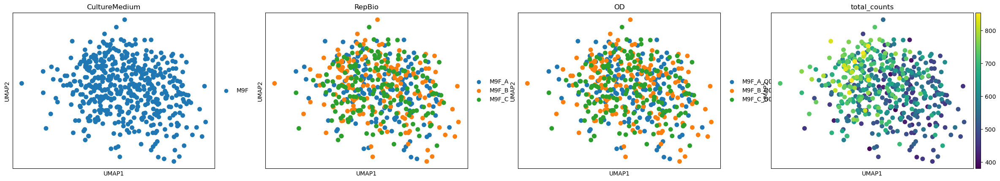

In [82]:
sc.pl.umap(
    adata_f,
    color=[
        "leiden_res_0.50",
        "leiden_res_0.75",
        "leiden_res_1.00",
        "leiden_res_1.50",
    ],
)

# %%
sc.pl.umap(adata_f, color=["CultureMedium", "RepBio", "OD", "total_counts"])




In [84]:
sc.pl.dotplot(
    adata_f,
    groupby="leiden_res_0.75",
    standard_scale="var",
    var_names=adata_f.var_names,
)

In [ ]:
# Perform differential expression analysis between clusters
sc.tl.rank_genes_groups(adata_f, groupby="leiden_res_0.75", method="wilcoxon")

# Get the top 5 differentially expressed genes for cluster 1
sc.get.rank_genes_groups_df(adata_f, group="1").head(5)

,names,scores,logfoldchanges,pvals,pvals_adj
0,QLH64-07835,2.562168,NaN,0.010402,0.999646
1,QLH64-04685,2.433838,NaN,0.014940,0.999646
2,QLH64-17250,2.193607,NaN,0.028264,0.999646
3,QLH64-29170,2.109237,NaN,0.034924,0.999646
4,QLH64-15675,1.835702,NaN,0.066402,0.999646


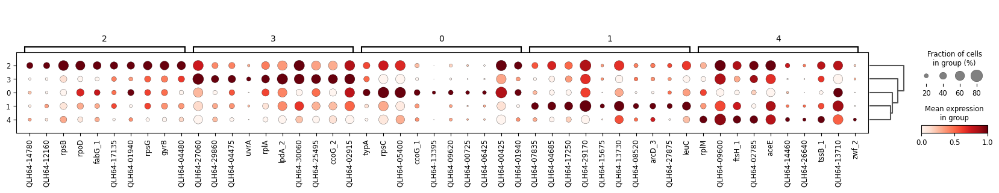

In [ ]:
sc.pl.rank_genes_groups_dotplot(
    adata_f, groupby="leiden_res_0.75", standard_scale="var", n_genes=10
)

In [103]:
sc.get.rank_genes_groups_df(adata_f, group="2").head(5)

,names,scores,logfoldchanges,pvals,pvals_adj
0,QLH64-14780,3.544575,NaN,0.000393,0.065276
1,QLH64-12160,3.489109,NaN,0.000485,0.065276
2,rpsB,3.474364,NaN,0.000512,0.065276
3,rpoD,3.469099,NaN,0.000522,0.065276
4,fabG_1,3.286200,NaN,0.001015,0.077475


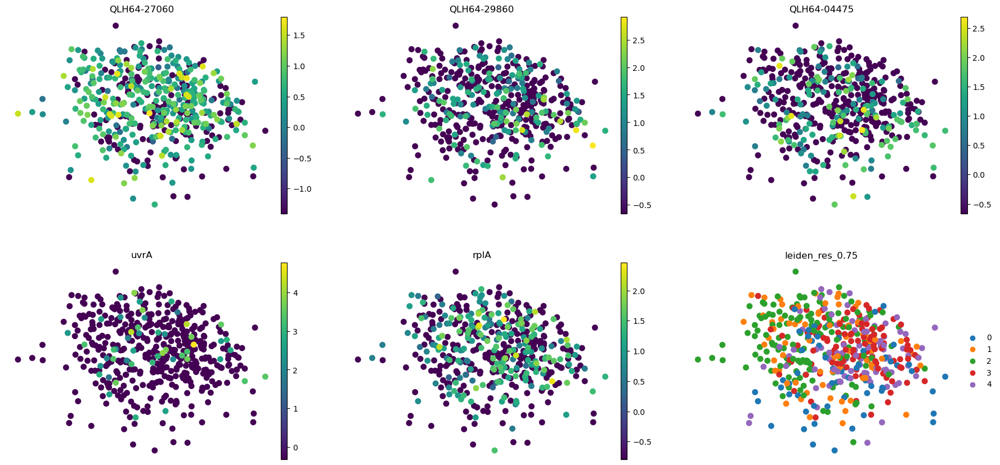

In [106]:
dc_cluster_genes = sc.get.rank_genes_groups_df(adata_f, group="3").head(5)["names"]
sc.pl.umap(
    adata_f,
    color=[*dc_cluster_genes, "leiden_res_0.75"],
    # legend_loc="on data",
    frameon=False,
    ncols=3,
)